# Heart-disease prediction workflow: monitored v3 analysis

## Read before running

This notebook combines the heart-disease modelling workflow, notebook resource
monitoring and separate summaries of two performance estimands. The saved outputs
document an executed analysis. Earlier analytical runs remain separate records.

1. Select the JupyterLab kernel containing the required packages.
2. Run the optional installation cell only if dependencies are missing, then
   restart the kernel.
3. For an execution check, use the smoke-test settings in Run controls.
4. Inspect the smoke-test assertions and monitoring records before starting a
   complete analysis. Smoke-test results are not final dissertation evidence.
5. For a complete analysis, set both final-run switches to True, save the notebook,
   restart the kernel and run all cells.
6. Avoid changing settings during execution. Record interruptions and substantial
   competing workloads rather than assuming they explain elapsed times.

The budget acknowledgement records the operator's declaration for that run.
It does not establish preregistration or demonstrate that earlier results were
unseen.

Two estimands are reported separately:

- the equal-weight mean of paired outer-fold differences in area under the
  receiver operating characteristic curve (ROC-AUC);
- differences between metrics calculated from averaged repeated out-of-fold
  (OOF) probabilities.

The bootstrap intervals apply only to the second estimand, conditional on the
saved predictions. They do not provide intervals or tests for the fold means.
The later joint directional hypothesis was formulated after analysis and did
not introduce an executed inferential test.

Notebook telemetry and stage-event records provide computational context.
They do not, by themselves, establish that hardware limitations, paging,
sleep or competing tasks caused a delay.

If execution fails, follow the cleanup instructions. Restarting the kernel
should not be treated as a substitute for orderly monitoring shutdown.

## Package installation — optional, run once, then restart the kernel
Uses the active kernel interpreter, not a different terminal Python. Leave the switch False after installation.

In [1]:
import subprocess
import sys

INSTALL_PACKAGES = False
requirements = ['numpy==2.2.4', 'pandas==2.2.3', 'scipy==1.15.2', 'scikit-learn==1.6.1', 'xgboost==2.1.4', 'pygad==3.7.0', 'pyswarms==1.3.0', 'matplotlib==3.10.1', 'seaborn==0.13.2']
if INSTALL_PACKAGES:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *requirements])
    subprocess.check_call([sys.executable, "-m", "pip", "check"])
    print("Installation complete. Restart the kernel before continuing.")
else:
    print("Installation skipped. Active kernel:", sys.executable)


Installation skipped. Active kernel: C:\Users\kama4\miniconda3\envs\kama_env\python.exe


## Run controls — the only place to choose smoke or final mode

Edit the two switches in the next cell. **Do not edit mode variables or budgets in Section 2.**

| Purpose | `FINAL_RUN` | `ACKNOWLEDGE_BUDGET_FREEZE` |
|---|---|---|
| Reduced smoke test (start here) | `False` | `False` |
| Complete analysis, after smoke checks pass | `True` | `True` |

`ACKNOWLEDGE_BUDGET_FREEZE = True` records your acknowledgement that the settings
for this new run are fixed. It does not prove that previous outer-test results were unseen.
Use smoke tests to check execution, not to choose budgets based on predictive performance.

Leave run monitoring at 5 seconds. After changing the switches, save the notebook, then select **Restart Kernel and Run All Cells**. Never change controls midway through a run. Section 2 derives the mode and constructs the configuration automatically. Different configurations receive different output-directory fingerprints.
However, matching configuration fingerprints alone do not establish that
checkpoints were produced using identical code, software or split contents.
Before reusing checkpoints in a future run, verify their provenance and
compatibility with the intended analysis.


In [2]:
from pathlib import Path
from types import SimpleNamespace
import os

FINAL_RUN = True
ACKNOWLEDGE_BUDGET_FREEZE = True
PROJECT_DIR = Path(r"C:\Users\kama4\Desktop\UEL_DS\Dissertation")
MONITOR_INTERVAL_SECONDS = 5.0

if FINAL_RUN and not ACKNOWLEDGE_BUDGET_FREEZE:
    raise ValueError("A final run requires an explicit budget-freeze acknowledgement.")
if not PROJECT_DIR.is_dir():
    raise FileNotFoundError(PROJECT_DIR)
if not 1 <= MONITOR_INTERVAL_SECONDS <= 3600:
    raise ValueError("Monitor interval must be between 1 and 3600 seconds")
OPTIONS = SimpleNamespace(final=FINAL_RUN,
                          acknowledge_budget_freeze=ACKNOWLEDGE_BUDGET_FREEZE,
                          monitor_interval=MONITOR_INTERVAL_SECONDS)
os.chdir(PROJECT_DIR)


## Monitoring and estimand helper definitions
The monitoring helpers record sampled system/process resources and modelling-stage
context. Available channels and sampling boundaries limit resource interpretation.

The paired-fold helper checks comparison keys and matched test hashes before
calculating condition-A minus condition-B ROC-AUC differences and their
equal-weight mean. The standard deviation describes variation across dependent
fold differences; it is not an inferential standard error.

In [3]:
"""Standard-library monitoring support embedded into the delivered workflow script."""
import atexit
import csv
import ctypes
import functools
import inspect
import json
import os
import platform
import shutil
import subprocess
import sys
import threading
import time
import uuid
from contextlib import contextmanager
from datetime import datetime, timezone
from pathlib import Path


def monitor_utc():
    return datetime.now(timezone.utc).isoformat()


def windows_snapshot():
    """Read current memory/CPU counters; missing fields are explicit on other OSs."""
    result = {"platform": platform.system(), "process_cpu_seconds": time.process_time()}
    if os.name != "nt":
        result["platform_counter_status"] = "Windows counters unavailable on this OS"
        return result
    from ctypes import wintypes

    class MemoryStatus(ctypes.Structure):
        _fields_ = [("length", wintypes.DWORD), ("load", wintypes.DWORD)] + [
            (name, ctypes.c_ulonglong) for name in [
                "total_phys", "available_phys", "total_pagefile", "available_pagefile",
                "total_virtual", "available_virtual", "available_extended",
            ]
        ]

    class ProcessMemory(ctypes.Structure):
        _fields_ = [("cb", wintypes.DWORD), ("page_fault_count", wintypes.DWORD)] + [
            (name, ctypes.c_size_t) for name in [
                "peak_working_set", "working_set", "peak_paged_pool", "paged_pool",
                "peak_nonpaged_pool", "nonpaged_pool", "pagefile_usage",
                "peak_pagefile_usage", "private_usage",
            ]
        ]

    class FileTime(ctypes.Structure):
        _fields_ = [("low", wintypes.DWORD), ("high", wintypes.DWORD)]

    kernel = ctypes.WinDLL("kernel32", use_last_error=True)
    memory = MemoryStatus(); memory.length = ctypes.sizeof(memory)
    kernel.GlobalMemoryStatusEx.argtypes = [ctypes.POINTER(MemoryStatus)]
    kernel.GlobalMemoryStatusEx.restype = wintypes.BOOL
    if not kernel.GlobalMemoryStatusEx(ctypes.byref(memory)):
        raise ctypes.WinError(ctypes.get_last_error())
    result.update({
        "total_ram_bytes": memory.total_phys,
        "available_ram_bytes": memory.available_phys,
        "memory_load_percent": memory.load,
        "commit_limit_bytes": memory.total_pagefile,
        "available_commit_bytes": memory.available_pagefile,
    })
    kernel.GetCurrentProcess.restype = wintypes.HANDLE
    process_handle = kernel.GetCurrentProcess()
    pm = ProcessMemory(); pm.cb = ctypes.sizeof(pm)
    psapi = ctypes.WinDLL("psapi", use_last_error=True)
    psapi.GetProcessMemoryInfo.argtypes = [wintypes.HANDLE, ctypes.POINTER(ProcessMemory), wintypes.DWORD]
    psapi.GetProcessMemoryInfo.restype = wintypes.BOOL
    if psapi.GetProcessMemoryInfo(process_handle, ctypes.byref(pm), pm.cb):
        result.update({"process_working_set_bytes": pm.working_set,
                       "process_private_bytes": pm.private_usage,
                       "process_page_fault_count": pm.page_fault_count})
    else:
        result["process_memory_error"] = str(ctypes.WinError(ctypes.get_last_error()))
    idle, kernel_time, user_time = FileTime(), FileTime(), FileTime()
    kernel.GetSystemTimes.argtypes = [ctypes.POINTER(FileTime)] * 3
    kernel.GetSystemTimes.restype = wintypes.BOOL
    if kernel.GetSystemTimes(ctypes.byref(idle), ctypes.byref(kernel_time), ctypes.byref(user_time)):
        unpack = lambda value: (value.high << 32) + value.low
        result["system_idle_ticks"] = unpack(idle)
        result["system_total_ticks"] = unpack(kernel_time) + unpack(user_time)
    return result


class RunMonitor:
    COUNTERS = [
        r"\Processor(_Total)\% Processor Time",
        r"\Memory\Available MBytes",
        r"\Memory\Committed Bytes",
        r"\Memory\Pages Input/sec",
        r"\Memory\Pages Output/sec",
        r"\PhysicalDisk(_Total)\Disk Bytes/sec",
        r"\Process(*)\ID Process",
        r"\Process(*)\% Processor Time",
        r"\Process(*)\Working Set",
    ]
    FIELDS = [
        "timestamp_utc", "session_id", "pid", "stage", "outer_split", "classifier",
        "selector", "seed", "condition", "elapsed_seconds", "sampling_gap_seconds",
        "process_cpu_seconds", "process_cpu_percent_one_core_basis", "system_cpu_percent",
        "total_ram_bytes", "available_ram_bytes", "memory_load_percent",
        "commit_limit_bytes", "available_commit_bytes", "process_working_set_bytes",
        "process_private_bytes", "process_page_fault_count", "sample_error",
    ]

    def __init__(self, output_dir, fingerprint, interval=5.0, enable_perfmon=True,
                 snapshot_provider=None, command_runner=None):
        if interval <= 0:
            raise ValueError("Monitoring interval must be positive")
        self.session_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:8]
        self.directory = Path(output_dir) / "monitoring" / self.session_id
        self.directory.mkdir(parents=True, exist_ok=False)
        self.fingerprint = fingerprint; self.interval = float(interval)
        self.enable_perfmon = enable_perfmon
        self.snapshot_provider = snapshot_provider or windows_snapshot
        self.command_runner = command_runner or subprocess.run
        self.lock = threading.RLock(); self.stop_event = threading.Event()
        self.context = {"stage": "initialisation"}; self.previous = None
        self.thread = None; self.stopped = False; self.samples = 0
        self.start_utc = monitor_utc(); self.start_clock = time.perf_counter()
        self.errors = []; self.commands = []; self.perfmon_started = False
        self.collector_name = "HDMonitor_" + str(os.getpid()) + "_" + uuid.uuid4().hex[:8]
        self.perfmon_status = "not requested"
        self.events = (self.directory / "stage_events.jsonl").open("w", encoding="utf-8")
        self.telemetry = (self.directory / "telemetry.csv").open("w", newline="", encoding="utf-8")
        self.writer = csv.DictWriter(self.telemetry, fieldnames=self.FIELDS)
        self.writer.writeheader(); self.telemetry.flush()
        self._save_status("created")

    def _command(self, args):
        flags = getattr(subprocess, "CREATE_NO_WINDOW", 0)
        try:
            result = self.command_runner(args, capture_output=True, text=True, timeout=20,
                                         creationflags=flags, errors="replace")
            record = {"timestamp_utc": monitor_utc(), "command": args,
                      "returncode": result.returncode, "stdout": result.stdout, "stderr": result.stderr}
        except Exception as exc:
            record = {"timestamp_utc": monitor_utc(), "command": args,
                      "returncode": None, "error": repr(exc)}
        self.commands.append(record)
        return record

    def event(self, event_type, **values):
        with self.lock:
            if self.events.closed:
                return
            row = {"timestamp_utc": monitor_utc(), "session_id": self.session_id,
                   "configuration_fingerprint": self.fingerprint, "pid": os.getpid(),
                   "event": event_type, **self.context, **values}
            self.events.write(json.dumps(row, ensure_ascii=False, default=str) + "\n")
            self.events.flush()

    def set_context(self, **values):
        with self.lock:
            self.context.update(values)

    def start(self):
        self.event("session_start")
        try:
            if self.enable_perfmon and os.name == "nt":
                executable = shutil.which("logman")
                if executable:
                    seconds = max(1, int(self.interval))
                    hours, remainder = divmod(seconds, 3600)
                    minutes, seconds = divmod(remainder, 60)
                    create = self._command([
                        executable, "create", "counter", self.collector_name,
                        "-o", str(self.directory / "system_perf"), "-f", "bin",
                        "-si", f"{hours:02d}:{minutes:02d}:{seconds:02d}", "-c", *self.COUNTERS,
                    ])
                    if create["returncode"] == 0:
                        started = self._command([executable, "start", self.collector_name])
                        self.perfmon_started = started["returncode"] == 0
                        self.perfmon_status = "running" if self.perfmon_started else "start failed"
                    else:
                        self.perfmon_status = "create failed; inspect counter names and access rights"
                else:
                    self.perfmon_status = "logman unavailable"
            elif self.enable_perfmon:
                self.perfmon_status = "Windows Performance Monitor unavailable on this OS"
            self._sample()
            self.thread = threading.Thread(target=self._loop, name="workflow-monitor", daemon=True)
            self.thread.start()
            self._save_status("running")
        except Exception as exc:
            self.errors.append(repr(exc)); self.perfmon_status = "startup incomplete"
            self._save_status("monitoring startup incomplete")
            raise
        return self

    def _sample(self):
        now = time.perf_counter()
        with self.lock:
            context = dict(self.context)
        row = {"timestamp_utc": monitor_utc(), "session_id": self.session_id,
               "pid": os.getpid(), **context, "elapsed_seconds": now - self.start_clock}
        try:
            snapshot = self.snapshot_provider()
            row.update({key: value for key, value in snapshot.items() if key in self.FIELDS})
            if self.previous:
                last_time, last_snapshot = self.previous
                gap = now - last_time; row["sampling_gap_seconds"] = gap
                if gap > 0:
                    row["process_cpu_percent_one_core_basis"] = 100 * (
                        snapshot["process_cpu_seconds"] - last_snapshot["process_cpu_seconds"]
                    ) / gap
                if "system_total_ticks" in snapshot and "system_total_ticks" in last_snapshot:
                    total = snapshot["system_total_ticks"] - last_snapshot["system_total_ticks"]
                    idle = snapshot["system_idle_ticks"] - last_snapshot["system_idle_ticks"]
                    if total > 0:
                        row["system_cpu_percent"] = 100 * (total - idle) / total
                if gap > 3 * self.interval:
                    self.event("sampling_gap", seconds=gap,
                               interpretation="Possible pause or scheduling delay; not proof of sleep")
            self.previous = (now, snapshot)
        except Exception as exc:
            row["sample_error"] = repr(exc)
            self.errors.append(repr(exc))
        with self.lock:
            self.writer.writerow({k: row.get(k, "") for k in self.FIELDS})
            self.telemetry.flush(); self.samples += 1

    def _loop(self):
        while not self.stop_event.wait(self.interval):
            try:
                self._sample()
            except Exception as exc:
                self.errors.append(repr(exc))
                self.event("monitor_error", message=repr(exc))

    @contextmanager
    def stage(self, label, **values):
        with self.lock:
            previous_context = dict(self.context)
            self.context.update({"stage": label, **values})
        event_id = uuid.uuid4().hex
        start_clock, start_cpu = time.perf_counter(), time.process_time()
        self.event("stage_start", event_id=event_id)
        status = "completed"
        try:
            yield
        except BaseException as exc:
            status = "interrupted" if isinstance(exc, KeyboardInterrupt) else "failed"
            self.event("stage_error", event_id=event_id, exception_type=type(exc).__name__)
            raise
        finally:
            self.event("stage_end", event_id=event_id, status=status,
                       elapsed_seconds=time.perf_counter()-start_clock,
                       process_cpu_seconds=time.process_time()-start_cpu)
            with self.lock:
                self.context = previous_context

    def _save_status(self, state):
        payload = {"session_id": self.session_id, "state": state,
                   "configuration_fingerprint": self.fingerprint,
                   "started_utc": self.start_utc, "updated_utc": monitor_utc(),
                   "pid": os.getpid(), "interval_seconds": self.interval,
                   "sample_count": self.samples, "perfmon_status": self.perfmon_status,
                   "errors": self.errors,
                   "platform": platform.platform(),
                   "processor_registry_name": self._processor_name(),
                   "interpretation": [
                       "Current telemetry cannot explain historical runs.",
                       "Process CPU time covers this Python process and its threads, not child processes.",
                       "Process CPU percent uses a one-core basis and can exceed 100 on multiple cores.",
                       "Page faults include soft faults; they do not prove disk paging.",
                       "Use Windows paging/disk counters and power events alongside sampling gaps.",
                       "Monitoring adds overhead; compare timing only within documented environments.",
                   ]}
        temp = self.directory / "monitor_status.json.tmp"
        temp.write_text(json.dumps(payload, indent=2), encoding="utf-8")
        temp.replace(self.directory / "monitor_status.json")

    @staticmethod
    def _processor_name():
        if os.name != "nt":
            return platform.processor()
        try:
            import winreg
            with winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE,
                               r"HARDWARE\DESCRIPTION\System\CentralProcessor\0") as key:
                return winreg.QueryValueEx(key, "ProcessorNameString")[0].strip()
        except OSError:
            return "unavailable"

    def stop(self, outcome="completed"):
        if self.stopped:
            return
        self.stop_event.set()
        if self.thread:
            self.thread.join(timeout=max(5, self.interval + 2))
            if self.thread.is_alive():
                raise RuntimeError("Telemetry writer did not stop; manifest must not be finalised")
        self._sample()
        stop_failure = False
        executable = shutil.which("logman")
        if self.perfmon_started and executable:
            result = self._command([executable, "stop", self.collector_name])
            stop_failure = result["returncode"] != 0
            self.perfmon_status = "stop failed; collector may still be active" if stop_failure else "stopped"
        if executable and self.enable_perfmon:
            self._command([executable, "delete", self.collector_name])
        if os.name == "nt" and self.enable_perfmon:
            wevtutil = shutil.which("wevtutil")
            if wevtutil:
                # Raw system power events help correlate pauses; no event is labelled as a cause automatically.
                end_utc = monitor_utc().replace("+00:00", "Z")
                start_utc = self.start_utc.replace("+00:00", "Z")
                query = ("*[System[(Provider[@Name='Microsoft-Windows-Kernel-Power'] or "
                         "Provider[@Name='Microsoft-Windows-Power-Troubleshooter']) and "
                         f"TimeCreated[@SystemTime>='{start_utc}' and @SystemTime<='{end_utc}']]]")
                record = self._command([wevtutil, "qe", "System", "/q:"+query, "/f:xml", "/c:1000"])
                if record["returncode"] == 0:
                    (self.directory / "power_events.xml").write_text(record["stdout"], encoding="utf-8")
                else:
                    self.errors.append("Power-event query unavailable; see perfmon_commands.json")
        self.event("session_end", outcome=outcome)
        self.events.close(); self.telemetry.close()
        (self.directory / "perfmon_commands.json").write_text(json.dumps(self.commands, indent=2), encoding="utf-8")
        (self.directory / "README.txt").write_text(
            "telemetry.csv contains timestamped system and current-Python-process observations.\n"
            "stage_events.jsonl links stages to outer split, classifier, condition, optimiser and seed.\n"
            "Open system_perf*.blg in Windows Performance Monitor when perfmon_status confirms collection.\n"
            "Process counters identify competing CPU/memory consumers by process instance and PID; no command lines are collected.\n"
            "Use Pages Input/sec and Pages Output/sec with available RAM and disk activity; page faults alone are insufficient.\n"
            "power_events.xml contains up to 1000 matching system power events in the session window.\n"
            "Missing power events or collection failures do not prove that no pause occurred.\n"
            "Checkpoint-reused results have no fresh fitting telemetry in this session.\n"
            "No performance metric, mask, fitness, search budget or stopping rule uses these observations.\n",
            encoding="utf-8")
        self.stopped = True
        self._save_status("failed to stop Performance Monitor" if stop_failure else outcome)
        if stop_failure:
            raise RuntimeError("Performance Monitor failed to stop; no stable final manifest can be claimed")


MONITOR = None


def monitor_stage(label):
    def decorate(function):
        signature = inspect.signature(function)
        @functools.wraps(function)
        def wrapped(*args, **kwargs):
            if MONITOR is None:
                return function(*args, **kwargs)
            values = signature.bind_partial(*args, **kwargs).arguments
            context = {target: values[name] for name, target in [
                ("classifier_name", "classifier"), ("split_id", "outer_split"), ("seed", "seed")
            ] if name in values}
            if label in {"GA", "PSO"}:
                context["selector"] = label
            with MONITOR.stage(label, **context):
                return function(*args, **kwargs)
        return wrapped
    return decorate


def monitoring_self_test():
    """Exercise telemetry, stage completion/failure and clean stop without fitting models."""
    from tempfile import TemporaryDirectory
    with TemporaryDirectory() as folder:
        monitor = RunMonitor(folder, "monitoring-self-test", interval=0.03, enable_perfmon=False,
                             snapshot_provider=lambda: {"process_cpu_seconds": time.process_time(),
                                                        "total_ram_bytes": 16 * 1024**3})
        monitor.start()
        with monitor.stage("synthetic-stage", outer_split=0, classifier="TEST", selector="PSO", seed=101):
            time.sleep(0.09)
        try:
            with monitor.stage("intentional-failure"):
                raise ValueError("self-test")
        except ValueError:
            pass
        monitor.stop(); monitor.stop()
        rows = list(csv.DictReader((monitor.directory / "telemetry.csv").open(encoding="utf-8")))
        events = [json.loads(line) for line in (monitor.directory / "stage_events.jsonl").read_text().splitlines()]
        assert len(rows) >= 2
        assert any(row["stage"] == "synthetic-stage" for row in rows)
        assert any(e["event"] == "stage_end" and e["status"] == "failed" for e in events)
        assert json.loads((monitor.directory / "monitor_status.json").read_text())["state"] == "completed"
        assert monitor.thread is not None and not monitor.thread.is_alive()
    print("Monitoring self-test passed; no analytical workflow was executed.")

"""Descriptive paired-fold summaries; no hypothesis test or fold bootstrap."""
import math
import statistics


def paired_fold_roc_auc(records, classifiers, expected_splits):
    """Match saved outer splits before subtracting A minus B, then average.

    Overlapping training samples make fold differences dependent. Their sample
    standard deviation describes spread only; it is not a standard error.
    """
    lookup = {}
    for record in records:
        key = (record['classifier'], record['condition'], int(record['outer_split']))
        if key in lookup:
            raise ValueError(f'Duplicate fold key: {key}')
        if not math.isfinite(float(record['roc_auc'])):
            raise ValueError(f'Non-finite fold ROC-AUC: {key}')
        lookup[key] = record
    expected = {(c, condition, split) for c in classifiers
                for condition in ('ALL', 'GA', 'PSO') for split in expected_splits}
    if set(lookup) != expected:
        raise ValueError('Fold keys do not exactly match the configured design')
    details, summaries = [], []
    for classifier in classifiers:
        for a, b in [('GA', 'ALL'), ('PSO', 'ALL'), ('GA', 'PSO')]:
            differences, values_a, values_b = [], [], []
            for split in expected_splits:
                left, right = lookup[classifier, a, split], lookup[classifier, b, split]
                for field in ('test_hash', 'repeat_id', 'fold_id'):
                    if left[field] != right[field]:
                        raise ValueError(f'Unmatched {field}: {classifier}, split {split}')
                va, vb = float(left['roc_auc']), float(right['roc_auc'])
                delta = va - vb
                values_a.append(va); values_b.append(vb); differences.append(delta)
                details.append(dict(classifier=classifier, condition_a=a, condition_b=b,
                                    comparison=f'{a} - {b}', outer_split=split,
                                    test_hash=left['test_hash'], repeat_id=left['repeat_id'],
                                    fold_id=left['fold_id'], roc_auc_a=va, roc_auc_b=vb,
                                    paired_fold_difference=delta))
            mean_delta = statistics.mean(differences)
            if not math.isclose(mean_delta, statistics.mean(values_a)-statistics.mean(values_b),
                                rel_tol=0, abs_tol=1e-12):
                raise AssertionError('Paired mean identity failed')
            summaries.append(dict(
                classifier=classifier, condition_a=a, condition_b=b, comparison=f'{a} - {b}',
                estimand_id='mean_paired_outer_fold_roc_auc_difference',
                hypothesis_role='approved contrast' if b == 'ALL' else 'secondary contrast',
                outer_split_count=len(differences), mean_roc_auc_a=statistics.mean(values_a),
                mean_roc_auc_b=statistics.mean(values_b), paired_mean_difference=mean_delta,
                descriptive_sd_difference=statistics.stdev(differences) if len(differences)>1 else None,
                direction='positive' if mean_delta>0 else 'negative' if mean_delta<0 else 'zero',
                uncertainty_scope='descriptive only; no hypothesis test, confidence interval or equivalence assessment',
                positive_split_count=sum(x>0 for x in differences),
                negative_split_count=sum(x<0 for x in differences),
                zero_split_count=sum(x==0 for x in differences)))
    return details, summaries

# Fixed provenance identifier of the v2 notebook used for this merge.
SOURCE_NOTEBOOK_SHA256 = 'b2ce58ade83487fd0e5a361495ecc73f380497d81196813a33a09908abbbb129'


# Comparative evaluation of genetic algorithm and particle swarm optimisation
# Feature selection for heart-disease prediction — monitored v3 workflow

The workflow compares five classifiers using the all-feature genetic algorithm.
(GA) and particle swarm optimisation (PSO) conditions using repeated outer
validation and training-stage selection and tuning.

Checksums document file identity. They do not establish data correctness.
representativeness, clinical validity or external validity. Integrity PASS rows
Record workflow checks and assertions; they are not an independent human review.

The analysis is an internal methodological benchmark. It does not establish
causal relationships, clinical readiness or diagnostic replacement.

## 1. Installation and imports

The optional installation cell uses the active kernel interpreter and specifies
package versions. After installation, restart the kernel before continuing.
The workflow records the versions actually available during execution.

Selected operations capture warnings locally. Warning coverage is incomplete:
some operations occur outside these contexts, and PyGAD warning suppression is
enabled. A zero captured-warning count therefore describes the saved log rather
than proving that no warning occurred.

In [4]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_3", outer_split="", classifier="", selector="", seed="", condition="")

    import hashlib
    import importlib.metadata as metadata
    import json
    import math
    import os
    import platform
    import random
    import time
    import urllib.request
    import warnings
    from contextlib import contextmanager
    import zipfile
    from dataclasses import asdict, dataclass
    from datetime import datetime, timezone
    from itertools import combinations
    from pathlib import Path
    from tempfile import TemporaryDirectory

    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    import pygad
    import pyswarms as ps
    import seaborn as sns
    import sklearn
    import xgboost
    from scipy.special import expit, logit
    from sklearn.base import clone
    from sklearn.calibration import CalibratedClassifierCV, calibration_curve
    from sklearn.compose import ColumnTransformer
    from sklearn.datasets import make_classification
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import (
        accuracy_score, average_precision_score, brier_score_loss,
        confusion_matrix, f1_score, matthews_corrcoef,
        precision_recall_curve, roc_auc_score, roc_curve,
    )
    from sklearn.model_selection import (
        GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
    )
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    from sklearn.svm import SVC
    from sklearn.tree import DecisionTreeClassifier
    from xgboost import XGBClassifier

    sns.set_theme(style="whitegrid", context="notebook")
    pd.set_option("display.max_columns", 100)
except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


## 2. Configuration — generated automatically; do not edit

This cell reads the Run controls above and constructs `CONFIG`, the settings actually used.
The `Config` class contains defaults; these do not override the values supplied by `CONFIG = Config(...)`. The configuration records computational settings, not independent evidence of
historical blinding or preregistration. The printed summary should agree with
the intended run mode before modelling begins.

| Automatically derived setting | Smoke test | Complete analysis |
|---|---|---|
| `FAST_MODE` | `True` | `False` |
| `ALLOW_FINAL_RUN` | `False` | `True` |
| Outer splits executed | 1 | 10 (5 folds × 2 repeats) |
| Optimiser seeds | 101 | 101, 202, 303 |
| Unique-mask request cap per optimiser run | 12 | 160 |
| GA population / PSO particles | 6 / 6 | 16 / 16 |
| Bootstrap replicates | 100 | 2,000 |

Smoke mode checks execution across all 15 classifier-condition combinations; it is not
final dissertation evidence. Both modes use the configured inner validation procedure.
Read the printed configuration summary to confirm the selected mode.
To change mode, return to **Run controls**, change its two switches, then restart the kernel
and run all cells. Do not manually change `FAST_MODE`, `ALLOW_FINAL_RUN` or class defaults here.


In [5]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_5", outer_split="", classifier="", selector="", seed="", condition="")
    @dataclass(frozen=True)
    class Config:
        workflow_version: str = "2.2.0-monitoring-estimands"
        monitoring_interval_seconds: float = OPTIONS.monitor_interval
        windows_perfmon_enabled: bool = True
        monitoring_version: str = "1.0.0"
        fast_mode: bool = True
        allow_final_run: bool = False
        random_state: int = 20260817
        outer_folds: int = 5
        outer_repeats: int = 2
        inner_folds: int = 3
        optimiser_seeds: tuple = (101,) if True else (101, 202, 303)
        fitness_eval_budget: int = 12 if True else 160
        bootstrap_replicates: int = 100 if True else 2000
        decision_threshold: float = 0.50
        n_jobs_outer: int = 1
        output_root: str = "workflow_outputs"
        checkpoint_dir: str = "workflow_outputs/checkpoints"
        source_url: str = "https://archive.ics.uci.edu/static/public/45/heart+disease.zip"
        source_member: str = "processed.cleveland.data"
        local_data_file: str = "data/processed.cleveland.data"
        expected_sha256: str = "a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f331b622b4efa0427c8"
        ga_population: int = 6 if True else 16
        pso_particles: int = 6 if True else 16
        fitness_tolerance: float = 1e-6


    # Automatically derived from Run controls; do not edit these variables here.

    FAST_MODE = not OPTIONS.final
    ALLOW_FINAL_RUN = OPTIONS.final

    CONFIG = Config(
        fast_mode=FAST_MODE,
        allow_final_run=ALLOW_FINAL_RUN,
        optimiser_seeds=(101,) if FAST_MODE else (101, 202, 303),
        fitness_eval_budget=12 if FAST_MODE else 160,
        bootstrap_replicates=100 if FAST_MODE else 2000,
        ga_population=6 if FAST_MODE else 16,
        pso_particles=6 if FAST_MODE else 16,
    )

    if CONFIG.fast_mode and CONFIG.allow_final_run:
        raise RuntimeError("Final analysis cannot run while FAST_MODE=True.")
    if not CONFIG.fast_mode and not CONFIG.allow_final_run:
        raise RuntimeError("Return to Run controls, set both final switches to True, then restart and run all cells.")
    if CONFIG.fitness_eval_budget % CONFIG.pso_particles != 0:
        raise ValueError("FITNESS_EVAL_BUDGET must be divisible by PSO particle count.")

    CLASSIFIERS = ["LR", "DT", "RF", "SVM", "XGB"]
    CONDITIONS = ["ALL", "GA", "PSO"]
    SELECTORS = ["GA", "PSO"]
    FEATURES = [
        "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
        "thalach", "exang", "oldpeak", "slope", "ca", "thal",
    ]
    TARGET = "num"
    NUMERIC_FEATURES = ["age", "trestbps", "chol", "thalach", "oldpeak"]
    CATEGORICAL_FEATURES = [
        "sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal",
    ]
    ALL_COLUMNS = FEATURES + [TARGET]

    outer_splits_to_run = 1 if CONFIG.fast_mode else CONFIG.outer_folds * CONFIG.outer_repeats
    units = outer_splits_to_run * len(CLASSIFIERS)
    upper_fitness_calls = units * len(SELECTORS) * len(CONFIG.optimiser_seeds) * CONFIG.fitness_eval_budget
    print(f"Mode: {'FAST smoke test' if CONFIG.fast_mode else 'FINAL'}")
    print(f"Outer classifier units: {units}")
    print(f"Upper bound on optimiser mask requests: {upper_fitness_calls:,}")
except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


Mode: FINAL
Outer classifier units: 50
Upper bound on optimiser mask requests: 48,000


## 3. Reproducibility and file utilities

Configuration fingerprints distinguish runs with different recorded settings.
The checkpoint loader checks the stored fingerprint and completion flag.
These checks do not independently verify identical code, software or checkpoint
contents.

Export formats have different precision properties. Prediction CSVs and
checkpoints support detailed numerical checks, while pandas JSON exports round
some numeric fields. Display tables apply additional rounding for presentation.

When reproducing rank-based metrics from saved CSVs, use round-trip floating-point
parsing so that numerical conversion does not unnecessarily change tied scores.

In [6]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_7", outer_split="", classifier="", selector="", seed="", condition="")
    # Provenance constant: this identifies the source v2 notebook, not this run.
    SOURCE_NOTEBOOK_SHA256 = 'b2ce58ade83487fd0e5a361495ecc73f380497d81196813a33a09908abbbb129'
    def set_global_seed(seed: int) -> None:
        """Seed Python and NumPy for repeatable stochastic operations."""
        os.environ["PYTHONHASHSEED"] = str(seed)
        random.seed(seed)
        np.random.seed(seed)


    def json_ready(value):
        """Convert common scientific-Python objects to JSON-safe values."""
        if isinstance(value, dict):
            return {str(k): json_ready(v) for k, v in value.items()}
        if isinstance(value, (list, tuple, set)):
            return [json_ready(v) for v in value]
        if isinstance(value, Path):
            return str(value)
        if isinstance(value, np.ndarray):
            return value.tolist()
        if isinstance(value, (np.integer,)):
            return int(value)
        if isinstance(value, (np.floating,)):
            return None if not np.isfinite(value) else float(value)
        if isinstance(value, (np.bool_,)):
            return bool(value)
        return value


    def save_json(data, path: Path) -> None:
        """Save JSON atomically enough for a single-process notebook run."""
        path.parent.mkdir(parents=True, exist_ok=True)
        temp = path.with_suffix(path.suffix + ".tmp")
        temp.write_text(json.dumps(json_ready(data), indent=2, sort_keys=True), encoding="utf-8")
        temp.replace(path)


    def sha256_file(path: Path) -> str:
        """Return a file's SHA-256 digest."""
        digest = hashlib.sha256()
        with path.open("rb") as handle:
            for chunk in iter(lambda: handle.read(1024 * 1024), b""):
                digest.update(chunk)
        return digest.hexdigest()


    def make_config_fingerprint(data) -> str:
        """Create a stable short fingerprint from JSON-serialisable settings."""
        payload = json.dumps(json_ready(data), sort_keys=True, separators=(",", ":"))
        return hashlib.sha256(payload.encode("utf-8")).hexdigest()[:16]


    def package_versions() -> dict:
        """Capture Python, platform and analytical package versions."""
        packages = [
            "numpy", "pandas", "scipy", "scikit-learn", "xgboost", "pygad",
            "pyswarms", "matplotlib", "seaborn", "joblib",
        ]
        versions = {name: metadata.version(name) for name in packages}
        versions.update({"python": platform.python_version(), "platform": platform.platform()})
        return versions


    set_global_seed(CONFIG.random_state)
    CONFIG_FINGERPRINT = make_config_fingerprint(asdict(CONFIG))
    RUN_NAME = f"{'fast_v3_mon' if CONFIG.fast_mode else 'final_v3_mon'}_{CONFIG_FINGERPRINT}"
    OUTPUT_DIR = Path(CONFIG.output_root) / RUN_NAME
    TABLE_DIR = OUTPUT_DIR / "tables"
    FIGURE_DIR = OUTPUT_DIR / "figures"
    CHECKPOINT_DIR = Path(CONFIG.checkpoint_dir) / RUN_NAME
    for folder in [OUTPUT_DIR, TABLE_DIR, FIGURE_DIR, CHECKPOINT_DIR]:
        folder.mkdir(parents=True, exist_ok=True)

    environment = package_versions()
    save_json(environment, OUTPUT_DIR / "software_versions.json")
    save_json(asdict(CONFIG), OUTPUT_DIR / "configuration.json")
    print(json.dumps(environment, indent=2))
    print("Configuration fingerprint:", CONFIG_FINGERPRINT)

    CAPTURED_WARNINGS = []

    @contextmanager
    def capture_warnings(section: str, operation: str, severity: str = "analytical"):
        """Capture warnings with provenance; never hide them globally."""
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            yield
        for item in caught:
            CAPTURED_WARNINGS.append({
                "timestamp_utc": datetime.now(timezone.utc).isoformat(),
                "category": item.category.__name__,
                "message": str(item.message),
                "section": section,
                "operation": operation,
                "severity": severity,
                "disposition": "recorded; execution continued",
            })


    def artifact_metadata(path: Path) -> dict:
        """Describe one canonical or alias artifact for the final manifest."""
        rel = str(path.relative_to(OUTPUT_DIR))
        suffix = path.suffix.lower()
        artifact_type = {".csv": "table", ".json": "machine-readable record", ".png": "figure"}.get(suffix, "artifact")
        producer = "figures" if "figures" in path.parts else "tables" if "tables" in path.parts else "workflow"
        alias_of = "tuning_results.json" if rel.replace("\\", "/") == "tables/best_hyperparameters_by_outer_split.json" else None
        grain_map = {
            "all_outer_predictions.csv": "observation × outer split × classifier × condition",
            "aggregated_oof_predictions.csv": "observation × classifier × condition",
            "fold_metrics.csv": "outer split × classifier × condition",
            "all_optimiser_runs.json": "outer split × classifier × selector × seed",
            "selected_masks.json": "outer split × classifier × condition",
            "tuning_results.json": "outer split × classifier × condition",
            "paired_bootstrap_differences.csv": "classifier × comparison × metric",
        }
        return {
            "relative_path": rel,
            "size_bytes": path.stat().st_size,
            "sha256": sha256_file(path),
            "artifact_type": artifact_type,
            "producing_section": producer,
            "row_or_key_grain": grain_map.get(path.name, "documented by producing table or record"),
            "precision_policy": "display-rounded" if "display_" in path.name else "full precision or lossless",
            "validation_rule": "size and SHA-256 verified after creation",
            "canonical": alias_of is None,
            "alias_of": alias_of,
        }


    # Separate monitor sessions prevent overwriting telemetry during checkpoint resume.
    MONITOR = RunMonitor(OUTPUT_DIR, CONFIG_FINGERPRINT,
                         interval=CONFIG.monitoring_interval_seconds,
                         enable_perfmon=CONFIG.windows_perfmon_enabled)
    MONITOR.start()
    atexit.register(MONITOR.stop, "process_exit")
    save_json({
        "recorded_utc": monitor_utc(), "configuration_fingerprint": CONFIG_FINGERPRINT,
        "source_notebook_sha256": SOURCE_NOTEBOOK_SHA256,
        "mode": "final" if OPTIONS.final else "smoke test",
        "operator_budget_freeze_acknowledgement": OPTIONS.acknowledge_budget_freeze,
        "meaning": "Operator acknowledgement for this new run, not independent proof about prior result inspection.",
        "historical_run_freeze_verified": False,
    }, OUTPUT_DIR / "run_authorisation_record.json")

except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


{
  "numpy": "2.2.4",
  "pandas": "2.2.3",
  "scipy": "1.15.2",
  "scikit-learn": "1.6.1",
  "xgboost": "2.1.4",
  "pygad": "3.7.0",
  "pyswarms": "1.3.0",
  "matplotlib": "3.10.1",
  "seaborn": "0.13.2",
  "joblib": "1.4.2",
  "python": "3.13.2",
  "platform": "Windows-11-10.0.26300-SP0"
}
Configuration fingerprint: c2c87bcc95ecdf7f


## 4. Data acquisition, provenance and verification

The executed analysis used an existing local processed Cleveland file.
The loader also provides a download fallback that selects the processed Cleveland
member from the University of California, Irvine (UCI) archive.

The loader checks the input checksum and schema, parses recognised missing-value
tokens and converts the original outcome to no disease (0) versus disease
(original values 1–4). Missing or incompatible input checks stop execution.

The provenance record identifies the acquisition route actually used and the
time of computational verification. That timestamp is not the date of patient
recruitment or original data collection. Checksum agreement establishes identity
with the configured reference file, not population representativeness..

Dataset: UCI Machine Learning Repository, *Heart Disease* (1988), https://doi.org/10.24432/C52P4X.

In [7]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_9", outer_split="", classifier="", selector="", seed="", condition="")
    def acquire_cleveland(config: Config) -> tuple[Path, str]:
        """Use the local verified file or download only UCI's Cleveland member."""
        path = Path(config.local_data_file)
        if path.exists():
            origin = "verified local copy supplied with notebook"
        else:
            path.parent.mkdir(parents=True, exist_ok=True)
            with TemporaryDirectory() as temp_dir:
                archive = Path(temp_dir) / "heart_disease.zip"
                urllib.request.urlretrieve(config.source_url, archive)
                with zipfile.ZipFile(archive) as zipped:
                    if config.source_member not in zipped.namelist():
                        raise RuntimeError("UCI archive does not contain processed.cleveland.data.")
                    path.write_bytes(zipped.read(config.source_member))
            origin = config.source_url
        observed_hash = sha256_file(path)
        if observed_hash != config.expected_sha256:
            raise RuntimeError(
                "Cleveland file checksum differs from the frozen analysis version. "
                f"Observed {observed_hash}; expected {config.expected_sha256}."
            )
        return path, origin


    def validate_dataset_schema(frame: pd.DataFrame) -> None:
        """Fail early if the frozen Cleveland schema or target coding is incompatible."""
        if frame.shape != (303, 14):
            raise ValueError(f"Expected Cleveland shape (303, 14), observed {frame.shape}.")
        if list(frame.columns) != ALL_COLUMNS:
            raise ValueError("Unexpected column names or order.")
        if frame[TARGET].isna().any():
            raise ValueError("Target contains missing values.")
        target_values = set(frame[TARGET].astype(int).unique())
        if not target_values.issubset({0, 1, 2, 3, 4}):
            raise ValueError(f"Unexpected original target values: {sorted(target_values)}")
        if len(FEATURES) != 13 or len(set(FEATURES)) != 13:
            raise ValueError("The analysis must contain 13 unique original predictors.")


    data_path, data_origin = acquire_cleveland(CONFIG)
    raw = pd.read_csv(
        data_path, header=None, names=ALL_COLUMNS,
        na_values=["?", "", "NA", "N/A"], skipinitialspace=True,
    )
    raw = raw.apply(pd.to_numeric, errors="coerce")
    validate_dataset_schema(raw)

    X = raw[FEATURES].copy()
    y_original = raw[TARGET].astype(int)
    y = (y_original > 0).astype(int).rename("heart_disease")
    X.index.name = "row_id"
    y.index = X.index

    provenance = {
        "source_url": CONFIG.source_url,
        "origin_used": data_origin,
        "retrieved_or_verified_utc": datetime.now(timezone.utc).isoformat(),
        "local_filename": str(data_path),
        "sha256": sha256_file(data_path),
        "raw_shape": list(raw.shape),
        "analytical_shape": [len(X), len(FEATURES)],
        "target_rule": "0=no heart disease; original values 1-4=heart disease",
        "original_target_counts": y_original.value_counts().sort_index().to_dict(),
        "binary_target_counts": y.value_counts().sort_index().to_dict(),
        "predictors": FEATURES,
        "numeric_predictors": NUMERIC_FEATURES,
        "categorical_predictors": CATEGORICAL_FEATURES,
        "duplicate_rows_retained": int(raw.duplicated().sum()),
    }
    save_json(provenance, OUTPUT_DIR / "data_provenance.json")
    display(pd.Series(provenance, name="value").to_frame())
except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


,value
source_url,https://archive.ics.uci.edu/static/public/45/h...
origin_used,verified local copy supplied with notebook
retrieved_or_verified_utc,2026-10-21T08:38:42.005812+00:00
local_filename,data\processed.cleveland.data
sha256,a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f...
raw_shape,"[303, 14]"
analytical_shape,"[303, 13]"
target_rule,0=no heart disease; original values 1-4=heart ...
original_target_counts,"{0: 164, 1: 55, 2: 36, 3: 35, 4: 13}"
binary_target_counts,"{0: 164, 1: 139}"


## 5. Focused exploratory analysis

Exploratory summaries describe the analytical sample, outcome distribution,
observed missingness and predictor values. They are not used by the code to
choose features, tuning settings or classification thresholds.

Duplicate rows are counted without automatic deletion. These summaries do not
establish predictor importance, causal relationships or a missingness mechanism.

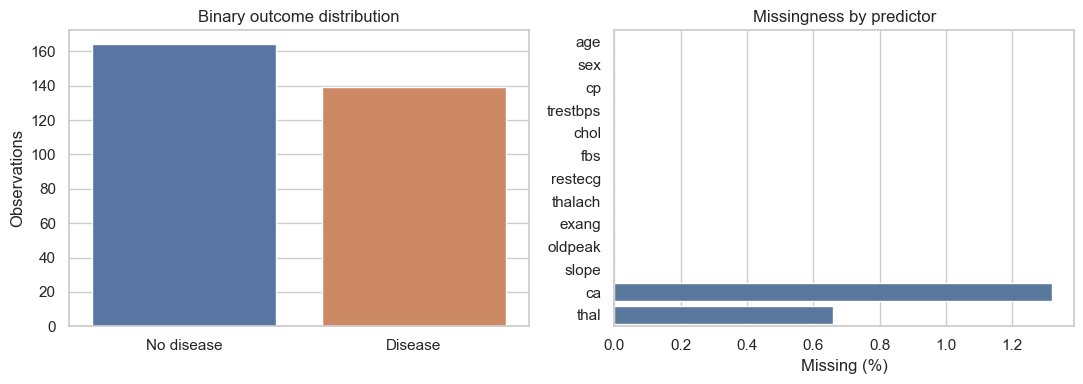

,feature,missing_n,missing_percent
0,age,0,0.000000
1,sex,0,0.000000
2,cp,0,0.000000
3,trestbps,0,0.000000
4,chol,0,0.000000
5,fbs,0,0.000000
6,restecg,0,0.000000
7,thalach,0,0.000000
8,exang,0,0.000000
9,oldpeak,0,0.000000


,feature,count,mean,std,min,25%,50%,75%,max
0,age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
1,trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
2,chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
3,thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
4,oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [8]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_11", outer_split="", classifier="", selector="", seed="", condition="")
    missingness = pd.DataFrame({
        "missing_n": X.isna().sum(),
        "missing_percent": X.isna().mean().mul(100),
    }).rename_axis("feature").reset_index()
    class_table = y.value_counts().sort_index().rename_axis("class").reset_index(name="n")
    class_table["label"] = class_table["class"].map({0: "No disease", 1: "Disease"})
    numeric_summary = X[NUMERIC_FEATURES].describe().T.reset_index(names="feature")
    categorical_frequencies = pd.concat(
        [
            X[name].value_counts(dropna=False).rename_axis("value").reset_index(name="n")
            .assign(feature=name)
            for name in CATEGORICAL_FEATURES
        ],
        ignore_index=True,
    )[["feature", "value", "n"]]

    class_table.to_csv(TABLE_DIR / "dataset_class_distribution.csv", index=False)
    missingness.to_csv(TABLE_DIR / "dataset_missingness.csv", index=False)
    numeric_summary.to_csv(TABLE_DIR / "dataset_numeric_summary.csv", index=False)
    categorical_frequencies.to_csv(TABLE_DIR / "dataset_categorical_frequencies.csv", index=False)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    sns.barplot(data=class_table, x="label", y="n", hue="label", legend=False, ax=axes[0])
    axes[0].set(title="Binary outcome distribution", xlabel="", ylabel="Observations")
    sns.barplot(data=missingness, x="missing_percent", y="feature", color="#4C78A8", ax=axes[1])
    axes[1].set(title="Missingness by predictor", xlabel="Missing (%)", ylabel="")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "01_class_and_missingness.png", dpi=300, bbox_inches="tight")
    plt.show()
    display(missingness, numeric_summary)
except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


## 6. Original-feature masks and fold-local pipelines

Each GA chromosome and PSO particle represents the 13 original predictors using
a binary mask. A selected original variable can produce multiple encoded columns,
so mask length and selected-variable count do not describe the fitted matrix width.

After original-variable selection, pipelines apply numeric imputation,
categorical imputation and one-hot encoding. Numeric standardisation is included
for logistic regression and support vector machine models. Each fitted
preprocessor learns its parameters from the training data supplied at that stage.

Dense encoded matrices are used for compatibility with the configured estimators..

In [9]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_13", outer_split="", classifier="", selector="", seed="", condition="")
    def validate_mask(mask, allow_empty: bool = False) -> tuple[int, ...]:
        """Validate and return a 13-bit original-feature mask."""
        cleaned = tuple(int(v) for v in np.asarray(mask).round().astype(int).tolist())
        if len(cleaned) != len(FEATURES):
            raise ValueError(f"Mask must have {len(FEATURES)} bits, not {len(cleaned)}.")
        if not set(cleaned).issubset({0, 1}):
            raise ValueError("Mask values must be binary.")
        if not allow_empty and sum(cleaned) == 0:
            raise ValueError("Empty feature masks cannot be fitted.")
        return cleaned


    def mask_to_features(mask) -> list[str]:
        """Translate a valid mask to original predictor names."""
        cleaned = validate_mask(mask)
        return [name for name, keep in zip(FEATURES, cleaned) if keep]


    def get_base_estimator(classifier_name: str, seed: int):
        """Return the fixed classifier used only inside wrapper fitness."""
        estimators = {
            "LR": LogisticRegression(C=1.0, solver="liblinear", max_iter=2000, random_state=seed),
            "DT": DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=seed),
            "RF": RandomForestClassifier(
                n_estimators=100, max_depth=5, min_samples_leaf=2,
                random_state=seed, n_jobs=1,
            ),
            "SVM": SVC(C=1.0, gamma="scale", kernel="rbf", probability=False, random_state=seed),
            "XGB": XGBClassifier(
                n_estimators=100, max_depth=3, learning_rate=0.05,
                objective="binary:logistic", eval_metric="logloss",
                random_state=seed, n_jobs=1, verbosity=0,
            ),
        }
        return estimators[classifier_name]


    def build_pipeline(classifier_name: str, selected_features: list[str], estimator) -> Pipeline:
        """Build imputation/encoding and classifier steps for selected original predictors."""
        selected_numeric = [f for f in NUMERIC_FEATURES if f in selected_features]
        selected_categorical = [f for f in CATEGORICAL_FEATURES if f in selected_features]
        numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
        if classifier_name in {"LR", "SVM"}:
            numeric_steps.append(("scaler", StandardScaler()))
        transformers = []
        if selected_numeric:
            transformers.append(("numeric", Pipeline(numeric_steps), selected_numeric))
        if selected_categorical:
            categorical_pipe = Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ])
            transformers.append(("categorical", categorical_pipe, selected_categorical))
        preprocessor = ColumnTransformer(transformers, remainder="drop", sparse_threshold=0)
        return Pipeline([("preprocess", preprocessor), ("model", estimator)])


    assert len(validate_mask(np.ones(13))) == 13
    assert mask_to_features(np.ones(13)) == FEATURES
    try:
        validate_mask(np.zeros(13))
        raise AssertionError("Empty mask test failed.")
    except ValueError:
        pass

    test_pipe = build_pipeline("LR", ["age", "cp"], get_base_estimator("LR", 1))
    test_pipe.fit(X[["age", "cp"]].iloc[:100], y.iloc[:100])
    encoded_width = test_pipe.named_steps["preprocess"].transform(X[["age", "cp"]].iloc[:5]).shape[1]
    assert encoded_width >= 2 and len(FEATURES) == 13
    print("Mask and pipeline checks passed; "
    "the original-variable mask length does not specify the encoded column count."
         )
except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


Mask and pipeline tests passed; encoded width is independent of mask length.


## 7. Frozen outer and inner splits

The complete analysis uses ten outer splits from five-fold stratified
cross-validation repeated twice. All classifier-condition combinations share
the same outer-test membership.

Within each outer-training set, one list of stratified inner partitions is
created and reused for wrapper fitness, condition-specific tuning and SVM
calibration. Selection is not repeated within every subsequent tuning or
calibration fold. Inner scores therefore require qualification, although
outer-test observations remain outside these development steps.

Repeated folds share observations and overlapping training sets; they are not
independent experiments.

In [10]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_15", outer_split="", classifier="", selector="", seed="", condition="")
    def index_hash(indices) -> str:
        """Hash an integer index array for split auditing."""
        return hashlib.sha256(np.asarray(indices, dtype=np.int64).tobytes()).hexdigest()[:16]


    def make_outer_splits(X_data, y_data, config: Config):
        """Generate the fixed repeated stratified outer splits and audit metadata."""
        splitter = RepeatedStratifiedKFold(
            n_splits=config.outer_folds,
            n_repeats=config.outer_repeats,
            random_state=config.random_state,
        )
        output = []
        for split_id, (train_idx, test_idx) in enumerate(splitter.split(X_data, y_data)):
            assert split_id // config.outer_folds < config.outer_repeats
            assert split_id % config.outer_folds in range(config.outer_folds)
            assert not set(train_idx).intersection(test_idx)
            output.append({
                "split_id": split_id,
                "repeat_id": split_id // config.outer_folds,
                "fold_id": split_id % config.outer_folds,
                "train_idx": train_idx,
                "test_idx": test_idx,
                "train_hash": index_hash(train_idx),
                "test_hash": index_hash(test_idx),
            })
        return output


    def make_inner_splits(y_outer_train: pd.Series, config: Config):
        """Create explicit frozen inner indices relative to the outer-training set."""
        splitter = StratifiedKFold(
            n_splits=config.inner_folds, shuffle=True, random_state=config.random_state,
        )
        dummy = np.zeros(len(y_outer_train))
        splits = [(tr.copy(), va.copy()) for tr, va in splitter.split(dummy, y_outer_train)]
        for train_idx, valid_idx in splits:
            assert not set(train_idx).intersection(valid_idx)
            assert y_outer_train.iloc[train_idx].nunique() == 2
            assert y_outer_train.iloc[valid_idx].nunique() == 2
        return splits


    outer_splits = make_outer_splits(X, y, CONFIG)
    split_metadata = pd.DataFrame([
        {k: v for k, v in split.items() if not k.endswith("_idx")}
        for split in outer_splits
    ])
    split_metadata.to_csv(OUTPUT_DIR / "outer_split_metadata.csv", index=False)
    assert len(outer_splits) == CONFIG.outer_folds * CONFIG.outer_repeats
    display(split_metadata)
except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


,split_id,repeat_id,fold_id,train_hash,test_hash
0,0,0,0,0f3aaab175b90696,2315226e178562f2
1,1,0,1,c07998fd1f95688f,8ca5a7669ada35b4
2,2,0,2,3dd1df095a6482e1,81d9af82e5511c3b
3,3,0,3,5919146b296c8aa9,6de8a53235058547
4,4,0,4,0bbd1e7e97a0a6ba,032edb474c9119e1
5,5,1,0,b2013221b43141fd,b1ff2787df2cc245
6,6,1,1,60813682433663e0,ea83d1dd94469e29
7,7,1,2,8220abd9a1458184,8e50afa1b253d9c8
8,8,1,3,997c89b9ce7e0142,336fcc1c02365367
9,9,1,4,f2c20aae37c65a00,6bc450f5d04dc7e9


## 8. Restrained classifier tuning grids

Each classifier uses the same parameter grid across the all-feature (ALL),
GA and PSO conditions. Smoke mode uses one setting per parameter to check
execution; complete mode uses the configured search grids.

Wrapper fitness uses fixed classifier settings before condition-specific tuning.
Feature selection and hyperparameter tuning are therefore sequential rather
than a joint search. The configured operations use one job to limit nested
parallel execution. The finite grids do not establish globally optimal settings.

In [11]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_17", outer_split="", classifier="", selector="", seed="", condition="")
    def get_param_grid(classifier_name: str, fast_mode: bool) -> dict:
        """Return the pre-specified model grid with pipeline prefixes."""
        full = {
            "LR": {"model__C": [0.1, 1.0, 10.0]},
            "DT": {"model__max_depth": [None, 3, 5], "model__min_samples_leaf": [1, 5, 10]},
            "RF": {
                "model__n_estimators": [150, 300], "model__max_depth": [None, 5],
                "model__min_samples_leaf": [1, 5],
            },
            "SVM": {"model__C": [0.1, 1.0, 10.0], "model__gamma": ["scale", 0.01, 0.1]},
            "XGB": {
                "model__n_estimators": [100, 200], "model__max_depth": [2, 3],
                "model__learning_rate": [0.03, 0.1],
            },
        }
        if not fast_mode:
            return full[classifier_name]
        base = get_base_estimator(classifier_name, CONFIG.random_state).get_params()
        keys = full[classifier_name].keys()
        return {key: [base[key.replace("model__", "")]] for key in keys}


    grid_inventory = []
    for classifier in CLASSIFIERS:
        for parameter, values in get_param_grid(classifier, CONFIG.fast_mode).items():
            grid_inventory.append({"classifier": classifier, "parameter": parameter, "values": values})
    grid_table = pd.DataFrame(grid_inventory)
    grid_table.to_csv(TABLE_DIR / "model_tuning_grids.csv", index=False)
    display(grid_table)
except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


,classifier,parameter,values
0,LR,model__C,"[0.1, 1.0, 10.0]"
1,DT,model__max_depth,"[None, 3, 5]"
2,DT,model__min_samples_leaf,"[1, 5, 10]"
3,RF,model__n_estimators,"[150, 300]"
4,RF,model__max_depth,"[None, 5]"
5,RF,model__min_samples_leaf,"[1, 5]"
6,SVM,model__C,"[0.1, 1.0, 10.0]"
7,SVM,model__gamma,"[scale, 0.01, 0.1]"
8,XGB,model__n_estimators,"[100, 200]"
9,XGB,model__max_depth,"[2, 3]"


## 9. Fitness evaluator and cache

For each nonempty mask, fitness is the mean inner-fold ROC-AUC from the
classifier-specific pipeline. SVM fitness uses decision scores; the other
classifiers use positive-class probabilities. Empty masks and recorded fitting
failures receive zero fitness.

Cache keys include the outer split, classifier, original-variable mask,
base-estimator settings, preprocessing metadata and inner-partition identities.
The optimiser label and search seed are excluded; the classifier's fitting seed
is fixed in the evaluator.

A run-level set counts unique nonempty masks requested, including requests
answered from the shared cache. Requests, cache misses and actual fits are
different quantities. GA runs precede PSO runs within each shared-cache unit,
which limits algorithm-only interpretation of runtime comparisons.

In [12]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_19", outer_split="", classifier="", selector="", seed="", condition="")
    FITNESS_ERRORS = []


    def estimator_fingerprint(estimator) -> str:
        """Fingerprint an estimator's complete parameter dictionary."""
        return make_config_fingerprint(estimator.get_params(deep=True))


    def inner_split_fingerprint(inner_splits) -> str:
        """Fingerprint explicit frozen inner indices."""
        representation = [
            {"train": index_hash(train), "valid": index_hash(valid)}
            for train, valid in inner_splits
        ]
        return make_config_fingerprint(representation)


    def evaluate_mask(
        mask, X_outer_train, y_outer_train, inner_splits, classifier_name,
        base_estimator, cache, context, run_state,
    ) -> float:
        """Return mean inner ROC-AUC for one original-feature mask."""
        run_state["attempted"] += 1
        cleaned = validate_mask(mask, allow_empty=True)
        if sum(cleaned) == 0:
            run_state["empty_masks"] += 1
            return 0.0
        if cleaned not in run_state["seen"]:
            if len(run_state["seen"]) >= run_state["budget"]:
                run_state["budget_rejections"] += 1
                return 0.0
            run_state["seen"].add(cleaned)

        cache_key = (
            context["outer_split"], classifier_name, cleaned,
            context["estimator_fingerprint"], context["preprocessing_fingerprint"],
            context["inner_split_fingerprint"],
        )
        if cache_key in cache:
            run_state["cache_hits"] += 1
            return cache[cache_key]

        selected = mask_to_features(cleaned)
        scores = []
        try:
            for train_idx, valid_idx in inner_splits:
                pipeline = build_pipeline(classifier_name, selected, clone(base_estimator))
                pipeline.fit(X_outer_train.iloc[train_idx][selected], y_outer_train.iloc[train_idx])
                if classifier_name == "SVM":
                    prediction = pipeline.decision_function(X_outer_train.iloc[valid_idx][selected])
                else:
                    prediction = pipeline.predict_proba(X_outer_train.iloc[valid_idx][selected])[:, 1]
                scores.append(roc_auc_score(y_outer_train.iloc[valid_idx], prediction))
            fitness = float(np.mean(scores))
        except Exception as exc:
            fitness = 0.0
            FITNESS_ERRORS.append({
                "outer_split": context["outer_split"], "classifier": classifier_name,
                "mask": cleaned, "error_type": type(exc).__name__, "message": str(exc),
            })
        cache[cache_key] = fitness
        run_state["cache_misses"] += 1
        return fitness


    def new_run_state(budget: int) -> dict:
        """Return transparent counters for one optimiser seed run."""
        return {
            "budget": budget, "seen": set(), "attempted": 0, "cache_hits": 0,
            "cache_misses": 0, "empty_masks": 0, "budget_rejections": 0,
        }
except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


## 10. Genetic Algorithm wrapper

PyGAD searches binary masks representing the original predictors. The workflow
saves the mask, recorded fitness, computational counters and history from every
configured seed run.

One run per outer-split/classifier combination supplies the GA prediction mask.
Runs within `1e-6` of the highest recorded fitness are ordered by fewer selected
predictors and then lower seed. This rule selects among saved runs; it does not
establish global optimality or remove model-selection uncertainty.

In [13]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_21", outer_split="", classifier="", selector="", seed="", condition="")
    @monitor_stage("GA")
    def run_ga(
        X_train, y_train, inner_splits, classifier_name, split_id,
        seed, cache, config: Config,
    ) -> dict:
        """Run one budgeted classifier-specific binary GA seed."""
        set_global_seed(seed)
        estimator = get_base_estimator(classifier_name, config.random_state)
        context = {
            "outer_split": split_id,
            "estimator_fingerprint": estimator_fingerprint(estimator),
            "preprocessing_fingerprint": make_config_fingerprint({
                "numeric": NUMERIC_FEATURES, "categorical": CATEGORICAL_FEATURES,
                "scaling": classifier_name in {"LR", "SVM"}, "dense": True,
            }),
            "inner_split_fingerprint": inner_split_fingerprint(inner_splits),
        }
        state = new_run_state(config.fitness_eval_budget)
        rng = np.random.default_rng(seed)
        initial = rng.integers(0, 2, size=(config.ga_population, len(FEATURES)))
        for row in initial:
            if row.sum() == 0:
                row[rng.integers(0, len(FEATURES))] = 1

        def fitness_function(ga_instance, solution, solution_index):
            return evaluate_mask(
                solution, X_train, y_train, inner_splits, classifier_name,
                estimator, cache, context, state,
            )

        def stop_at_budget(ga_instance):
            return "stop" if len(state["seen"]) >= state["budget"] else None

        generations = max(1, math.ceil(config.fitness_eval_budget / config.ga_population))
        start = time.perf_counter()
        ga = pygad.GA(
            num_generations=generations,
            num_parents_mating=max(2, config.ga_population // 2),
            initial_population=initial,
            fitness_func=fitness_function,
            gene_type=int,
            gene_space=[0, 1],
            parent_selection_type="tournament",
            K_tournament=3,
            crossover_type="single_point",
            crossover_probability=0.8,
            mutation_type="random",
            mutation_probability=0.1,
            mutation_by_replacement=True,
            random_mutation_min_val=0,
            random_mutation_max_val=2,
            keep_elitism=1,
            on_generation=stop_at_budget,
            random_seed=seed,
            save_best_solutions=True,
            suppress_warnings=True,
        )
        ga.run()
        solution, fitness, _ = ga.best_solution()
        mask = validate_mask(solution)
        elapsed = time.perf_counter() - start
        return {
            "outer_split": split_id, "classifier": classifier_name, "selector": "GA",
            "seed": seed, "mask": mask, "features": mask_to_features(mask),
            "fitness": float(fitness), "feature_count": int(sum(mask)),
            "population_size": config.ga_population, "max_generations": generations,
            "parent_selection": "tournament", "crossover": "single_point:0.8",
            "mutation": "random:0.1", "runtime_seconds": elapsed,
            "attempted_evaluations": state["attempted"],
            "unique_requested": len(state["seen"]), "cache_hits": state["cache_hits"],
            "cache_misses": state["cache_misses"],
            "termination": "fitness budget reached" if len(state["seen"]) >= state["budget"] else "generation limit",
            "convergence": [float(v) for v in ga.best_solutions_fitness],
        }
except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


## 11. Binary Particle Swarm Optimisation wrapper

PySwarms minimises cost, so the supplied objective is `negative mean inner-fold
ROC-AUC`. PSO uses the same configured seed set and unique-mask request cap as GA,
but generations and iterations are not equivalent computational units.

The implementation uses binary positions, sigmoid-transformed velocities and
dynamic neighbourhoods. Its recorded neighbourhood-cost history should not be
described as a uniformly monotone best-so-far fitness trajectory.

The library obtains the returned cost and position through separate operations.
Their numerical correspondence was not independently verified for every saved
run. The histories, stopping rule and returned values therefore do not establish
global optimality.

In [14]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_23", outer_split="", classifier="", selector="", seed="", condition="")
    @monitor_stage("PSO")
    def run_binary_pso(
        X_train, y_train, inner_splits, classifier_name, split_id,
        seed, cache, config: Config,
    ) -> dict:
        """Run one budgeted classifier-specific BinaryPSO seed."""
        set_global_seed(seed)
        estimator = get_base_estimator(classifier_name, config.random_state)
        context = {
            "outer_split": split_id,
            "estimator_fingerprint": estimator_fingerprint(estimator),
            "preprocessing_fingerprint": make_config_fingerprint({
                "numeric": NUMERIC_FEATURES, "categorical": CATEGORICAL_FEATURES,
                "scaling": classifier_name in {"LR", "SVM"}, "dense": True,
            }),
            "inner_split_fingerprint": inner_split_fingerprint(inner_splits),
        }
        state = new_run_state(config.fitness_eval_budget)

        def objective(particles):
            fitness = [
                evaluate_mask(
                    particle, X_train, y_train, inner_splits, classifier_name,
                    estimator, cache, context, state,
                )
                for particle in particles
            ]
            return -np.asarray(fitness, dtype=float)

        rng = np.random.default_rng(seed)
        initial = rng.integers(0, 2, size=(config.pso_particles, len(FEATURES)))
        for row in initial:
            if row.sum() == 0:
                row[rng.integers(0, len(FEATURES))] = 1
        options = {"c1": 1.5, "c2": 1.5, "w": 0.7, "k": min(3, config.pso_particles), "p": 2}
        iterations = config.fitness_eval_budget // config.pso_particles
        start = time.perf_counter()
        optimiser = ps.discrete.BinaryPSO(
            n_particles=config.pso_particles,
            dimensions=len(FEATURES), options=options, init_pos=initial,
        )
        best_cost, best_position = optimiser.optimize(objective, iters=iterations, verbose=False)
        mask = validate_mask(best_position)
        elapsed = time.perf_counter() - start
        return {
            "outer_split": split_id, "classifier": classifier_name, "selector": "PSO",
            "seed": seed, "mask": mask, "features": mask_to_features(mask),
            "fitness": float(-best_cost), "feature_count": int(sum(mask)),
            "swarm_size": config.pso_particles, "max_iterations": iterations,
            "c1": options["c1"], "c2": options["c2"], "w": options["w"],
            "neighbourhood_k": options["k"], "distance_p": options["p"],
            "runtime_seconds": elapsed, "attempted_evaluations": state["attempted"],
            "unique_requested": len(state["seen"]), "cache_hits": state["cache_hits"],
            "cache_misses": state["cache_misses"],
            "termination": "fixed matched evaluation batches",
            "convergence": [float(-v) for v in optimiser.cost_history],
        }


    def choose_best_run(runs: list[dict], tolerance: float) -> dict:
        """Choose by inner fitness, parsimony within tolerance, then lower seed."""
        best_fitness = max(run["fitness"] for run in runs)
        tied = [run for run in runs if best_fitness - run["fitness"] <= tolerance]
        return sorted(tied, key=lambda run: (run["feature_count"], run["seed"]))[0]
except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


## 12. Optimiser and cache smoke tests

These reduced checks exercise mask validation, request-budget handling and
cache-context behaviour before the main experiment. Smoke models and caches
are separate from those used in the main outer-split/classifier units.

Their success supports execution checking; it does not independently validate
the complete analysis or demonstrate that every possible leakage route is absent.
Section 14 runs the selected smoke or complete experiment.

In [15]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_25", outer_split="", classifier="", selector="", seed="", condition="")
    smoke_split = outer_splits[0]
    smoke_train = smoke_split["train_idx"]
    X_smoke, y_smoke = X.iloc[smoke_train], y.iloc[smoke_train]
    inner_smoke = make_inner_splits(y_smoke, CONFIG)
    smoke_cache = {}

    # Independent synthetic-data smoke test with the same 13-feature schema.
    synthetic_values, synthetic_target = make_classification(
        n_samples=120, n_features=13, n_informative=6, n_redundant=2,
        random_state=CONFIG.random_state,
    )
    X_synthetic = pd.DataFrame(synthetic_values, columns=FEATURES)
    for feature in CATEGORICAL_FEATURES:
        X_synthetic[feature] = pd.qcut(
            X_synthetic[feature], q=3, labels=False, duplicates="drop"
        ).astype(float)
    y_synthetic = pd.Series(synthetic_target, name="heart_disease")
    synthetic_inner = make_inner_splits(y_synthetic, CONFIG)
    synthetic_cache = {}
    synthetic_ga = run_ga(
        X_synthetic, y_synthetic, synthetic_inner, "LR", "synthetic", 101,
        synthetic_cache, CONFIG,
    )
    synthetic_pso = run_binary_pso(
        X_synthetic, y_synthetic, synthetic_inner, "LR", "synthetic", 101,
        synthetic_cache, CONFIG,
    )
    assert sum(synthetic_ga["mask"]) > 0 and sum(synthetic_pso["mask"]) > 0
    assert synthetic_ga["unique_requested"] <= CONFIG.fitness_eval_budget
    assert synthetic_pso["unique_requested"] <= CONFIG.fitness_eval_budget

    ga_smoke = run_ga(
        X_smoke, y_smoke, inner_smoke, "LR", 0, 101, smoke_cache, CONFIG,
    )
    pso_smoke = run_binary_pso(
        X_smoke, y_smoke, inner_smoke, "LR", 0, 101, smoke_cache, CONFIG,
    )
    assert len(ga_smoke["mask"]) == len(FEATURES) and sum(ga_smoke["mask"]) > 0
    assert len(pso_smoke["mask"]) == len(FEATURES) and sum(pso_smoke["mask"]) > 0
    assert ga_smoke["unique_requested"] <= CONFIG.fitness_eval_budget
    assert pso_smoke["unique_requested"] <= CONFIG.fitness_eval_budget

    # The cache key shape contains no optimiser seed; seed changes can reuse a deterministic mask score.
    sample_cache_key = next(iter(smoke_cache))
    assert len(sample_cache_key) == 6 and 101 not in sample_cache_key
    print("Optimiser smoke tests passed.")
    display(pd.DataFrame([ga_smoke, pso_smoke]).drop(columns=["mask", "features", "convergence"]))
except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


Optimiser smoke tests passed.


,outer_split,classifier,selector,seed,fitness,feature_count,population_size,max_generations,parent_selection,crossover,mutation,runtime_seconds,attempted_evaluations,unique_requested,cache_hits,cache_misses,termination,swarm_size,max_iterations,c1,c2,w,neighbourhood_k,distance_p
0,0,LR,GA,101,0.895692,11,16.0,10.0,tournament,single_point:0.8,random:0.1,18.868373,150,132,18,132,generation limit,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0,LR,PSO,101,0.896334,10,NaN,NaN,NaN,NaN,NaN,8.348269,160,74,102,58,fixed matched evaluation batches,16.0,10.0,1.5,1.5,0.7,3.0,2.0


## 13. Final tuning and held-out prediction

Original-variable selection is completed before condition-specific grid search.
The selected subset is tuned using the frozen inner partitions, and the chosen
pipeline is refitted on the outer-training data before predicting the held-out
outer test.

For SVM, decision scores guide selection and tuning. A sigmoid calibrator is
then fitted using outer-training data with the configured inner partitions and
`ensemble=False`. The chosen subset and tuning decisions are not independently
reselected within each calibration fold.

Best inner scores describe the adaptive search process; they are not substitutes
for outer-test performance estimates.

In [16]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_27", outer_split="", classifier="", selector="", seed="", condition="")
    @monitor_stage("tuning_and_prediction")
    def tune_and_evaluate(
        X_train, y_train, X_test, selected_features, inner_splits,
        classifier_name, config: Config,
    ) -> dict:
        """Tune inside outer training, refit and predict untouched outer test data."""
        estimator = get_base_estimator(classifier_name, config.random_state)
        pipeline = build_pipeline(classifier_name, selected_features, estimator)
        search = GridSearchCV(
            pipeline, get_param_grid(classifier_name, config.fast_mode),
            scoring="roc_auc", cv=inner_splits, refit=True,
            n_jobs=1, return_train_score=False, error_score="raise",
        )
        start = time.perf_counter()
        with capture_warnings("13", f"GridSearchCV:{classifier_name}"):
            search.fit(X_train[selected_features], y_train)
        if classifier_name == "SVM":
            calibrated = CalibratedClassifierCV(
                estimator=clone(search.best_estimator_), method="sigmoid",
                cv=inner_splits, n_jobs=1, ensemble=False,
            )
            with capture_warnings("13", "SVM sigmoid calibration"):
                calibrated.fit(X_train[selected_features], y_train)
            probabilities = calibrated.predict_proba(X_test[selected_features])[:, 1]
            decision_scores = search.best_estimator_.decision_function(X_test[selected_features])
            fitted_model = calibrated
        else:
            probabilities = search.best_estimator_.predict_proba(X_test[selected_features])[:, 1]
            decision_scores = probabilities.copy()
            fitted_model = search.best_estimator_
        return {
            "probabilities": np.asarray(probabilities),
            "decision_scores": np.asarray(decision_scores),
            "best_params": search.best_params_,
            "best_inner_auc": float(search.best_score_),
            "runtime_seconds": time.perf_counter() - start,
            "fitted_model": fitted_model,
            "calibration_method": "sigmoid" if classifier_name == "SVM" else None,
            "calibration_ensemble": False if classifier_name == "SVM" else None,
            "calibration_training_hash": index_hash(X_train.index.to_numpy()) if classifier_name == "SVM" else None,
        }


    def compute_binary_metrics(y_true, probabilities, threshold: float = 0.50) -> dict:
        """Calculate discrimination, threshold and calibration metrics safely."""
        y_true = np.asarray(y_true, dtype=int)
        probabilities = np.asarray(probabilities, dtype=float)
        predicted = (probabilities >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
        metrics = {
            "roc_auc": roc_auc_score(y_true, probabilities) if np.unique(y_true).size == 2 else np.nan,
            "pr_auc": average_precision_score(y_true, probabilities) if np.unique(y_true).size == 2 else np.nan,
            "mcc": matthews_corrcoef(y_true, predicted),
            "sensitivity": tp / (tp + fn) if tp + fn else np.nan,
            "specificity": tn / (tn + fp) if tn + fp else np.nan,
            "f1": f1_score(y_true, predicted, zero_division=0),
            "accuracy": accuracy_score(y_true, predicted),
            "brier": brier_score_loss(y_true, probabilities),
        }
        try:
            clipped = np.clip(probabilities, 1e-6, 1 - 1e-6)
            calibration_model = LogisticRegression(C=np.inf, solver="lbfgs", max_iter=2000)
            with capture_warnings("15", "calibration intercept and slope", "analytical"):
                calibration_model.fit(logit(clipped).reshape(-1, 1), y_true)
            metrics["calibration_intercept"] = float(calibration_model.intercept_[0])
            metrics["calibration_slope"] = float(calibration_model.coef_[0, 0])
            metrics["calibration_status"] = "estimated"
        except Exception as exc:
            metrics["calibration_intercept"] = np.nan
            metrics["calibration_slope"] = np.nan
            metrics["calibration_status"] = f"not estimable: {type(exc).__name__}"
        return metrics
except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


## 14. Main repeated nested-CV experiment

Each outer split freezes one inner-partition list. Within each classifier,
the workflow runs all GA seeds followed by all PSO seeds using a shared cache.
It selects one mask per selector using the recorded inner-fitness and tie-breaking
rule, then tunes and assesses ALL, GA and PSO in condition order.

Predictions, fold metrics, optimiser summaries, selected masks and tuning records
are saved for each completed outer-split/classifier unit. Existing checkpoints
may bypass fresh fitting when the current loader accepts them; their provenance
must therefore be considered when interpreting execution and monitoring records.

In [17]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_29", outer_split="", classifier="", selector="", seed="", condition="")
    def save_checkpoint(unit: dict, path: Path) -> None:
        """Save a completed outer-split-by-classifier unit."""
        save_json(unit, path)


    def load_checkpoint(path: Path, fingerprint: str):
        """Load only a complete compatible checkpoint."""
        if not path.exists():
            return None
        data = json.loads(path.read_text(encoding="utf-8"))
        if data.get("config_fingerprint") != fingerprint or not data.get("complete"):
            return None
        return data


    prediction_rows = []
    fold_metric_rows = []
    optimiser_runs = []
    selected_mask_rows = []
    tuning_rows = []

    splits_for_run = outer_splits[:1] if CONFIG.fast_mode else outer_splits
    for split in splits_for_run:
        split_id = split["split_id"]
        train_idx, test_idx = split["train_idx"], split["test_idx"]
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        inner_splits = make_inner_splits(y_train, CONFIG)

        for classifier in CLASSIFIERS:
            MONITOR.set_context(stage="outer_unit", outer_split=split_id, classifier=classifier,
                                selector="", seed="", condition="")
            checkpoint_path = CHECKPOINT_DIR / f"split_{split_id:02d}_{classifier}.json"
            checkpoint = load_checkpoint(checkpoint_path, CONFIG_FINGERPRINT)
            if checkpoint is not None:
                MONITOR.event("checkpoint_reused", path=str(checkpoint_path), fitting_telemetry="not re-executed in this session")
                prediction_rows.extend(checkpoint["predictions"])
                fold_metric_rows.extend(checkpoint["fold_metrics"])
                optimiser_runs.extend(checkpoint["optimiser_runs"])
                selected_mask_rows.extend(checkpoint["selected_masks"])
                tuning_rows.extend(checkpoint["tuning"])
                continue

            unit_predictions, unit_metrics = [], []
            unit_runs, unit_masks, unit_tuning = [], [], []
            cache = {}
            condition_masks = {"ALL": tuple([1] * len(FEATURES))}

            ga_runs = [
                run_ga(X_train, y_train, inner_splits, classifier, split_id, seed, cache, CONFIG)
                for seed in CONFIG.optimiser_seeds
            ]
            pso_runs = [
                run_binary_pso(X_train, y_train, inner_splits, classifier, split_id, seed, cache, CONFIG)
                for seed in CONFIG.optimiser_seeds
            ]
            chosen_ga = choose_best_run(ga_runs, CONFIG.fitness_tolerance)
            chosen_pso = choose_best_run(pso_runs, CONFIG.fitness_tolerance)
            condition_masks.update({"GA": chosen_ga["mask"], "PSO": chosen_pso["mask"]})
            unit_runs.extend(ga_runs + pso_runs)

            for condition in CONDITIONS:
                MONITOR.set_context(condition=condition, selector="", seed="")
                mask = condition_masks[condition]
                selected = mask_to_features(mask)
                fitted = tune_and_evaluate(
                    X_train, y_train, X_test, selected, inner_splits, classifier, CONFIG,
                )
                probabilities = fitted["probabilities"]
                predicted = (probabilities >= CONFIG.decision_threshold).astype(int)
                metrics = compute_binary_metrics(y_test, probabilities, CONFIG.decision_threshold)
                metric_row = {
                    "outer_split": split_id, "repeat_id": split["repeat_id"],
                    "fold_id": split["fold_id"], "test_hash": split["test_hash"],
                    "classifier": classifier, "condition": condition,
                    "feature_count": len(selected), **metrics,
                }
                unit_metrics.append(metric_row)
                unit_masks.append({
                    "outer_split": split_id, "classifier": classifier, "condition": condition,
                    "mask": mask, "features": selected, "feature_count": len(selected),
                    "selected_by_inner_only": True,
                })
                unit_tuning.append({
                    "outer_split": split_id, "classifier": classifier, "condition": condition,
                    "best_inner_auc": fitted["best_inner_auc"],
                    "best_params": fitted["best_params"],
                    "runtime_seconds": fitted["runtime_seconds"],
                    "calibration_method": fitted["calibration_method"],
                    "calibration_ensemble": fitted["calibration_ensemble"],
                    "calibration_training_hash": fitted["calibration_training_hash"],
                })
                for local_position, row_id in enumerate(test_idx):
                    unit_predictions.append({
                        "row_id": int(row_id), "outer_split": split_id,
                        "repeat_id": split["repeat_id"], "fold_id": split["fold_id"],
                        "classifier": classifier, "condition": condition,
                        "y_true": int(y_test.iloc[local_position]),
                        "probability": float(probabilities[local_position]),
                        "predicted_class": int(predicted[local_position]),
                        "decision_score": float(fitted["decision_scores"][local_position]),
                        "mask_id": "".join(map(str, mask)),
                        "test_hash": split["test_hash"],
                    })

            unit = {
                "config_fingerprint": CONFIG_FINGERPRINT, "complete": True,
                "outer_split": split_id, "classifier": classifier,
                "predictions": unit_predictions, "fold_metrics": unit_metrics,
                "optimiser_runs": unit_runs, "selected_masks": unit_masks,
                "tuning": unit_tuning,
            }
            save_checkpoint(unit, checkpoint_path)
            prediction_rows.extend(unit_predictions)
            fold_metric_rows.extend(unit_metrics)
            optimiser_runs.extend(unit_runs)
            selected_mask_rows.extend(unit_masks)
            tuning_rows.extend(unit_tuning)
            print(f"Completed split {split_id}, {classifier}")

    predictions = pd.DataFrame(prediction_rows).drop_duplicates(
        ["row_id", "outer_split", "classifier", "condition"], keep="last"
    )
    fold_metrics = pd.DataFrame(fold_metric_rows).drop_duplicates(
        ["outer_split", "classifier", "condition"], keep="last"
    )
    optimiser_runs_df = pd.DataFrame(optimiser_runs).drop_duplicates(
        ["outer_split", "classifier", "selector", "seed"], keep="last"
    )
    selected_masks = pd.DataFrame(selected_mask_rows).drop_duplicates(
        ["outer_split", "classifier", "condition"], keep="last"
    )
    tuning_results = pd.DataFrame(tuning_rows).drop_duplicates(
        ["outer_split", "classifier", "condition"], keep="last"
    )

    predictions.to_csv(OUTPUT_DIR / "all_outer_predictions.csv", index=False)
    fold_metrics.to_csv(OUTPUT_DIR / "fold_metrics.csv", index=False)
    optimiser_runs_df.to_json(OUTPUT_DIR / "all_optimiser_runs.json", orient="records", indent=2)
    selected_masks.to_json(OUTPUT_DIR / "selected_masks.json", orient="records", indent=2)
    tuning_results.to_json(OUTPUT_DIR / "tuning_results.json", orient="records", indent=2)
    pd.DataFrame(
        FITNESS_ERRORS,
        columns=["outer_split", "classifier", "mask", "error_type", "message"],
    ).to_csv(OUTPUT_DIR / "fitness_errors.csv", index=False)
    display(fold_metrics.head(15))
except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


Completed split 0, LR
Completed split 0, DT
Completed split 0, RF
Completed split 0, SVM
Completed split 0, XGB
Completed split 1, LR
Completed split 1, DT
Completed split 1, RF
Completed split 1, SVM
Completed split 1, XGB
Completed split 2, LR
Completed split 2, DT
Completed split 2, RF
Completed split 2, SVM
Completed split 2, XGB
Completed split 3, LR
Completed split 3, DT
Completed split 3, RF
Completed split 3, SVM
Completed split 3, XGB
Completed split 4, LR
Completed split 4, DT
Completed split 4, RF
Completed split 4, SVM
Completed split 4, XGB
Completed split 5, LR
Completed split 5, DT
Completed split 5, RF
Completed split 5, SVM
Completed split 5, XGB
Completed split 6, LR
Completed split 6, DT
Completed split 6, RF
Completed split 6, SVM
Completed split 6, XGB
Completed split 7, LR
Completed split 7, DT
Completed split 7, RF
Completed split 7, SVM
Completed split 7, XGB
Completed split 8, LR
Completed split 8, DT
Completed split 8, RF
Completed split 8, SVM
Completed split

,outer_split,repeat_id,fold_id,test_hash,classifier,condition,feature_count,roc_auc,pr_auc,mcc,sensitivity,specificity,f1,accuracy,brier,calibration_intercept,calibration_slope,calibration_status
0,0,0,0,2315226e178562f2,LR,ALL,13,0.978355,0.976294,0.869164,0.892857,0.969697,0.925926,0.934426,0.078605,0.211736,2.915752,estimated
1,0,0,0,2315226e178562f2,LR,GA,8,0.979437,0.980552,0.901199,0.928571,0.969697,0.945455,0.950820,0.084066,0.448444,3.762208,estimated
2,0,0,0,2315226e178562f2,LR,PSO,9,0.978355,0.978495,0.901199,0.928571,0.969697,0.945455,0.950820,0.086272,0.402245,3.523721,estimated
3,0,0,0,2315226e178562f2,DT,ALL,13,0.889610,0.846074,0.669913,0.821429,0.848485,0.821429,0.836066,0.143645,-0.144923,0.832714,estimated
4,0,0,0,2315226e178562f2,DT,GA,6,0.933442,0.933684,0.673143,0.857143,0.818182,0.827586,0.836066,0.094924,-0.086923,1.565639,estimated
5,0,0,0,2315226e178562f2,DT,PSO,6,0.935606,0.929934,0.768734,0.857143,0.909091,0.872727,0.885246,0.096583,-0.349084,1.485375,estimated
6,0,0,0,2315226e178562f2,RF,ALL,13,0.977273,0.978352,0.835855,0.928571,0.909091,0.912281,0.918033,0.090934,-0.338909,3.578960,estimated
7,0,0,0,2315226e178562f2,RF,GA,9,0.974026,0.972222,0.840350,0.964286,0.878788,0.915254,0.918033,0.089442,-0.375530,3.017362,estimated
8,0,0,0,2315226e178562f2,RF,PSO,9,0.977273,0.977483,0.835855,0.928571,0.909091,0.912281,0.918033,0.080088,-0.194263,2.726153,estimated
9,0,0,0,2315226e178562f2,SVM,ALL,13,0.974026,0.969605,0.867965,0.928571,0.939394,0.928571,0.934426,0.072766,0.150102,2.063142,estimated


## 15. Descriptive fold-level performance

Outer-fold means and standard deviations are descriptive because repeated cross-validation scores are correlated. They are not treated as independent observations, and no ordinary t-test or naïve fold-based confidence interval is used (Bengio and Grandvalet, 2004).

### Paired outer-fold ROC-AUC differences

For each classifier and matched outer split, the workflow calculates
condition-A minus condition-B ROC-AUC. It then reports the equal-weight mean,
sample standard deviation and direction counts across splits.

GA−ALL and PSO−ALL correspond to the original hypothesis contrasts; GA−PSO is
secondary. These are descriptive summaries of dependent folds, without a
fold-based confidence interval or hypothesis test.

The later joint directional framework was formulated after analysis. It does
not retrospectively change these calculations or provide a joint inferential test.

In [18]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_31", outer_split="", classifier="", selector="", seed="", condition="")
    METRIC_COLUMNS = [
        "roc_auc", "pr_auc", "mcc", "sensitivity", "specificity", "f1",
        "accuracy", "brier", "calibration_intercept", "calibration_slope",
    ]
    fold_summary = (
        fold_metrics.groupby(["classifier", "condition"])[METRIC_COLUMNS]
        .agg(["mean", "std"]).reset_index()
    )
    fold_summary.columns = [
        "_".join([str(part) for part in column if part]).rstrip("_")
        if isinstance(column, tuple) else column
        for column in fold_summary.columns
    ]
    fold_summary.to_csv(TABLE_DIR / "descriptive_outer_fold_performance.csv", index=False)
    display(fold_summary)

    # HYPOTHESIS ESTIMAND: mean of matched outer-fold AUC differences.
    # Do not attach aggregated-probability bootstrap intervals to these estimates.
    fold_difference_rows, fold_difference_summaries = paired_fold_roc_auc(
        fold_metrics.to_dict("records"), CLASSIFIERS,
        list(range(1 if CONFIG.fast_mode else 10)),
    )
    paired_fold_differences = pd.DataFrame(fold_difference_rows)
    fold_hypothesis_summary = pd.DataFrame(fold_difference_summaries)
    paired_fold_differences.to_csv(TABLE_DIR / "paired_outer_fold_roc_auc_differences.csv", index=False)
    fold_hypothesis_summary.to_csv(TABLE_DIR / "outer_fold_roc_auc_contrast_summary.csv", index=False)
    save_json({
        "hypothesis_estimand": "equal-weight mean of matched outer-fold ROC-AUC differences",
        "secondary_estimand": "difference of ROC-AUCs calculated from averaged OOF probabilities",
        "hypothesis_inference": "descriptive direction only; no new test or interval",
        "bootstrap_scope": "conditional on realised aggregated OOF predictions; not an interval for the fold-mean hypothesis estimand",
        "smoke_mode": CONFIG.fast_mode,
        "configuration_fingerprint": CONFIG_FINGERPRINT,
        "chapter_correction_rule": "Register new deterministic summaries separately; correct Chapter 4 through a traceable amendment, never silently through Discussion.",
    }, OUTPUT_DIR / "analysis_estimands.json")
    display(fold_hypothesis_summary)

except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


,classifier,condition,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,mcc_mean,mcc_std,sensitivity_mean,sensitivity_std,specificity_mean,specificity_std,f1_mean,f1_std,accuracy_mean,accuracy_std,brier_mean,brier_std,calibration_intercept_mean,calibration_intercept_std,calibration_slope_mean,calibration_slope_std
0,DT,ALL,0.847910,0.059668,0.818290,0.079804,0.611008,0.136152,0.780159,0.074841,0.823390,0.116461,0.786519,0.066168,0.803907,0.069620,0.155711,0.048168,-0.030475,0.241516,0.663084,0.470134
1,DT,GA,0.845536,0.056507,0.820855,0.070592,0.604613,0.079669,0.740741,0.098203,0.850189,0.082879,0.771086,0.048796,0.800301,0.039358,0.157438,0.037015,-0.070400,0.188426,0.422318,0.422078
2,DT,PSO,0.852263,0.059875,0.827626,0.078474,0.595577,0.131743,0.758333,0.077104,0.829261,0.103213,0.774939,0.067054,0.797104,0.066701,0.154709,0.046075,-0.134104,0.188488,0.375982,0.431759
3,LR,ALL,0.911091,0.052859,0.910943,0.049387,0.696556,0.134019,0.794841,0.085058,0.893182,0.069177,0.827499,0.075800,0.848361,0.065781,0.117255,0.033443,0.125861,0.295375,1.552894,0.773376
4,LR,GA,0.906171,0.044239,0.903948,0.043635,0.687686,0.132236,0.805556,0.081757,0.875000,0.087478,0.825420,0.071035,0.843333,0.066566,0.120938,0.026722,0.061675,0.248275,1.280498,0.904281
5,LR,PSO,0.904235,0.050663,0.904456,0.045979,0.677786,0.158793,0.794709,0.088531,0.875000,0.098453,0.819353,0.083903,0.838443,0.079333,0.122393,0.033149,0.094435,0.330986,1.397032,0.896348
6,RF,ALL,0.908797,0.056640,0.906800,0.055335,0.653773,0.165900,0.780556,0.107469,0.865720,0.083792,0.804653,0.093609,0.826967,0.081267,0.125657,0.029801,0.145294,0.392390,1.877393,0.902596
7,RF,GA,0.899758,0.049003,0.893312,0.050079,0.660420,0.111539,0.801720,0.081412,0.853504,0.072952,0.811932,0.060891,0.830027,0.055477,0.129056,0.029326,0.122985,0.330033,1.509873,0.795757
8,RF,PSO,0.905009,0.046377,0.899657,0.050374,0.654055,0.124041,0.791005,0.087121,0.856534,0.078716,0.806947,0.069517,0.826831,0.061404,0.125136,0.029750,0.145954,0.390098,1.548158,0.652538
9,SVM,ALL,0.908243,0.051632,0.908815,0.046905,0.673363,0.140930,0.805556,0.076798,0.862784,0.087371,0.819815,0.074671,0.836803,0.070454,0.121090,0.039796,0.009992,0.228295,1.126458,0.483379


,classifier,condition_a,condition_b,comparison,estimand_id,hypothesis_role,outer_split_count,mean_roc_auc_a,mean_roc_auc_b,paired_mean_difference,descriptive_sd_difference,direction,uncertainty_scope,positive_split_count,negative_split_count,zero_split_count
0,LR,GA,ALL,GA - ALL,mean_paired_outer_fold_roc_auc_difference,approved contrast,10,0.906171,0.911091,-0.004921,0.014081,negative,"descriptive only; no hypothesis test, confiden...",3,7,0
1,LR,PSO,ALL,PSO - ALL,mean_paired_outer_fold_roc_auc_difference,approved contrast,10,0.904235,0.911091,-0.006856,0.012688,negative,"descriptive only; no hypothesis test, confiden...",3,7,0
2,LR,GA,PSO,GA - PSO,mean_paired_outer_fold_roc_auc_difference,secondary contrast,10,0.906171,0.904235,0.001936,0.011795,positive,"descriptive only; no hypothesis test, confiden...",4,5,1
3,DT,GA,ALL,GA - ALL,mean_paired_outer_fold_roc_auc_difference,approved contrast,10,0.845536,0.847910,-0.002374,0.029155,negative,"descriptive only; no hypothesis test, confiden...",3,7,0
4,DT,PSO,ALL,PSO - ALL,mean_paired_outer_fold_roc_auc_difference,approved contrast,10,0.852263,0.847910,0.004353,0.038234,positive,"descriptive only; no hypothesis test, confiden...",6,4,0
5,DT,GA,PSO,GA - PSO,mean_paired_outer_fold_roc_auc_difference,secondary contrast,10,0.845536,0.852263,-0.006727,0.026699,negative,"descriptive only; no hypothesis test, confiden...",4,5,1
6,RF,GA,ALL,GA - ALL,mean_paired_outer_fold_roc_auc_difference,approved contrast,10,0.899758,0.908797,-0.009039,0.014675,negative,"descriptive only; no hypothesis test, confiden...",2,8,0
7,RF,PSO,ALL,PSO - ALL,mean_paired_outer_fold_roc_auc_difference,approved contrast,10,0.905009,0.908797,-0.003787,0.019112,negative,"descriptive only; no hypothesis test, confiden...",4,5,1
8,RF,GA,PSO,GA - PSO,mean_paired_outer_fold_roc_auc_difference,secondary contrast,10,0.899758,0.905009,-0.005251,0.010014,negative,"descriptive only; no hypothesis test, confiden...",2,6,2
9,SVM,GA,ALL,GA - ALL,mean_paired_outer_fold_roc_auc_difference,approved contrast,10,0.901525,0.908243,-0.006718,0.017498,negative,"descriptive only; no hypothesis test, confiden...",3,7,0


## 16. Aggregated repeated out-of-fold predictions

In complete mode, each observation receives one held-out prediction per repeat.
Probabilities are averaged separately for each observation, classifier and
condition, then thresholded again for aggregated classification metrics.

Metrics calculated from these averaged probabilities are different quantities
from means of fold-level metrics. Their differences can have different directions.

Smoke mode covers one outer fold and does not provide complete repeated OOF
coverage of the sample.

In [19]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_33", outer_split="", classifier="", selector="", seed="", condition="")
    def aggregate_repeated_oof_predictions(prediction_frame: pd.DataFrame) -> pd.DataFrame:
        """Average repeated OOF probabilities to one aligned row per observation and condition."""
        grouped = prediction_frame.groupby(
            ["row_id", "classifier", "condition"], as_index=False
        ).agg(
            y_true=("y_true", "first"),
            probability=("probability", "mean"),
            prediction_count=("probability", "size"),
        )
        grouped["predicted_class"] = (grouped["probability"] >= CONFIG.decision_threshold).astype(int)
        if not CONFIG.fast_mode:
            assert grouped["prediction_count"].eq(CONFIG.outer_repeats).all()
        assert not grouped.duplicated(["row_id", "classifier", "condition"]).any()
        return grouped


    aggregated_predictions = aggregate_repeated_oof_predictions(predictions)
    aggregated_predictions.to_csv(OUTPUT_DIR / "aggregated_oof_predictions.csv", index=False)

    aggregated_metric_rows = []
    for (classifier, condition), group in aggregated_predictions.groupby(["classifier", "condition"]):
        aggregated_metric_rows.append({
            "classifier": classifier, "condition": condition,
            "n_observations": len(group),
            **compute_binary_metrics(group["y_true"], group["probability"], CONFIG.decision_threshold),
        })
    aggregated_metrics = pd.DataFrame(aggregated_metric_rows)
    aggregated_metrics.to_csv(TABLE_DIR / "aggregated_oof_performance.csv", index=False)
    display(aggregated_metrics)
except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


,classifier,condition,n_observations,roc_auc,pr_auc,mcc,sensitivity,specificity,f1,accuracy,brier,calibration_intercept,calibration_slope,calibration_status
0,DT,ALL,303,0.866490,0.853427,0.607157,0.748201,0.853659,0.779026,0.805281,0.143717,-0.082352,0.752988,estimated
1,DT,GA,303,0.867477,0.849493,0.642248,0.741007,0.890244,0.792308,0.821782,0.139955,-0.017106,0.648827,estimated
2,DT,PSO,303,0.876535,0.869543,0.640454,0.776978,0.859756,0.800000,0.821782,0.137197,-0.143641,0.458106,estimated
3,LR,ALL,303,0.913581,0.904346,0.707928,0.798561,0.902439,0.834586,0.854785,0.115808,0.061825,1.309714,estimated
4,LR,GA,303,0.908098,0.892014,0.660572,0.784173,0.871951,0.810409,0.831683,0.117587,0.028647,1.092321,estimated
5,LR,PSO,303,0.905685,0.884227,0.660494,0.798561,0.859756,0.813187,0.831683,0.119021,0.007781,1.154040,estimated
6,RF,ALL,303,0.910291,0.905319,0.633822,0.784173,0.847561,0.798535,0.818482,0.124815,0.081085,1.550293,estimated
7,RF,GA,303,0.902746,0.894688,0.640454,0.776978,0.859756,0.800000,0.821782,0.126180,0.086460,1.318804,estimated
8,RF,PSO,303,0.908756,0.898546,0.660494,0.798561,0.859756,0.813187,0.831683,0.122808,0.086752,1.406154,estimated
9,SVM,ALL,303,0.908800,0.904579,0.647588,0.805755,0.841463,0.808664,0.825083,0.119817,-0.053879,0.984665,estimated


## 17. Paired, outcome-stratified bootstrap differences

For each classifier, the bootstrap samples observations with replacement within
each outcome class. Identical sampled indices are applied to both conditions
before calculating GA−ALL, PSO−ALL or GA−PSO metric differences.

Percentile intervals describe sampling variation conditional on the realised
aggregated OOF predictions and the fixed class counts. Preprocessing, selection,
tuning and model fitting are not repeated within the bootstrap.

These intervals do not quantify full model-development uncertainty, provide
intervals for paired fold means or test the later joint directional proposition.

### Alignment of the two estimands

The alignment table places paired fold-mean differences beside
aggregated-prediction differences and their conditional intervals. It preserves
their separate definitions and reports direction disagreements without treating
one estimate as a correction to the other.

In [20]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_35", outer_split="", classifier="", selector="", seed="", condition="")
    def bootstrap_metric(y_true, probabilities, metric_name: str, threshold: float):
        """Calculate one named metric from probabilities."""
        y_true = np.asarray(y_true, dtype=int)
        probabilities = np.asarray(probabilities, dtype=float)
        if metric_name == "roc_auc":
            return roc_auc_score(y_true, probabilities)
        if metric_name == "pr_auc":
            return average_precision_score(y_true, probabilities)
        if metric_name == "brier":
            return brier_score_loss(y_true, probabilities)
        if metric_name == "mcc":
            predicted = (probabilities >= threshold).astype(int)
            return matthews_corrcoef(y_true, predicted)
        raise ValueError(f"Unsupported bootstrap metric: {metric_name}")


    def paired_stratified_bootstrap(
        aligned: pd.DataFrame, condition_a: str, condition_b: str,
        metric_name: str, replicates: int, seed: int, threshold: float,
    ) -> dict:
        """Bootstrap an aligned condition-A minus condition-B metric difference."""
        required = {"row_id", "y_true", condition_a, condition_b}
        if not required.issubset(aligned.columns):
            raise ValueError(f"Aligned frame lacks: {required - set(aligned.columns)}")
        y_values = aligned["y_true"].to_numpy(dtype=int)
        prob_a = aligned[condition_a].to_numpy(dtype=float)
        prob_b = aligned[condition_b].to_numpy(dtype=float)
        observed = bootstrap_metric(y_values, prob_a, metric_name, threshold) - bootstrap_metric(
            y_values, prob_b, metric_name, threshold
        )
        rng = np.random.default_rng(seed)
        class_indices = [np.flatnonzero(y_values == label) for label in [0, 1]]
        differences = []
        skipped = 0
        for _ in range(replicates):
            sampled = np.concatenate([
                rng.choice(indices, size=len(indices), replace=True) for indices in class_indices
            ])
            rng.shuffle(sampled)
            try:
                value_a = bootstrap_metric(y_values[sampled], prob_a[sampled], metric_name, threshold)
                value_b = bootstrap_metric(y_values[sampled], prob_b[sampled], metric_name, threshold)
                difference = value_a - value_b
                if np.isfinite(difference):
                    differences.append(difference)
                else:
                    skipped += 1
            except Exception:
                skipped += 1
        if not differences:
            lower = upper = np.nan
        else:
            lower, upper = np.percentile(differences, [2.5, 97.5])
        return {
            "condition_a": condition_a, "condition_b": condition_b,
            "comparison": f"{condition_a} - {condition_b}", "metric": metric_name,
            "observed_difference": float(observed), "ci_2_5": float(lower),
            "ci_97_5": float(upper), "valid_replicates": len(differences),
            "skipped_replicates": skipped, "bootstrap_seed": seed,
            "interval_scope": "conditional on aggregated OOF predictions",
        }


    bootstrap_rows = []
    comparisons_to_run = [("GA", "ALL"), ("PSO", "ALL"), ("GA", "PSO")]
    bootstrap_metrics = ["roc_auc", "pr_auc", "mcc", "brier"]
    for classifier in CLASSIFIERS:
        subset = aggregated_predictions.query("classifier == @classifier")
        aligned = subset.pivot(index=["row_id", "y_true"], columns="condition", values="probability").reset_index()
        if not set(CONDITIONS).issubset(aligned.columns):
            continue
        for metric_name in bootstrap_metrics:
            for condition_a, condition_b in comparisons_to_run:
                result = paired_stratified_bootstrap(
                    aligned, condition_a, condition_b, metric_name,
                    CONFIG.bootstrap_replicates, CONFIG.random_state, CONFIG.decision_threshold,
                )
                bootstrap_rows.append({"classifier": classifier, **result})

    paired_bootstrap = pd.DataFrame(bootstrap_rows)
    # SECONDARY ESTIMAND: these intervals do not test the approved fold-mean hypotheses.
    paired_bootstrap["estimand_id"] = "metric_difference_from_averaged_oof_probabilities"
    paired_bootstrap["hypothesis_role"] = "not direct evidence for the mean-outer-fold hypothesis"
    paired_bootstrap.to_csv(TABLE_DIR / "paired_bootstrap_differences.csv", index=False)
    display(paired_bootstrap.query("metric == 'roc_auc'"))

    # Compare directions transparently; disagreement is valid, not an error to repair.
    oof_roc = paired_bootstrap.query("metric == 'roc_auc'")[[
        "classifier", "comparison", "observed_difference", "ci_2_5", "ci_97_5", "interval_scope"
    ]].rename(columns={"observed_difference": "aggregated_oof_roc_auc_difference",
                       "ci_2_5": "aggregated_oof_ci_lower", "ci_97_5": "aggregated_oof_ci_upper"})
    estimand_alignment = fold_hypothesis_summary.merge(
        oof_roc, on=["classifier", "comparison"], validate="one_to_one")
    estimand_alignment["directions_agree"] = (
        np.sign(estimand_alignment["paired_mean_difference"]) ==
        np.sign(estimand_alignment["aggregated_oof_roc_auc_difference"]))
    estimand_alignment.to_csv(TABLE_DIR / "estimand_alignment_summary.csv", index=False)

except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


,classifier,condition_a,condition_b,comparison,metric,observed_difference,ci_2_5,ci_97_5,valid_replicates,skipped_replicates,bootstrap_seed,interval_scope,estimand_id,hypothesis_role
0,LR,GA,ALL,GA - ALL,roc_auc,-0.005483,-0.018513,0.007239,2000,0,20260817,conditional on aggregated OOF predictions,metric_difference_from_averaged_oof_probabilities,not direct evidence for the mean-outer-fold hy...
1,LR,PSO,ALL,PSO - ALL,roc_auc,-0.007896,-0.021758,0.005486,2000,0,20260817,conditional on aggregated OOF predictions,metric_difference_from_averaged_oof_probabilities,not direct evidence for the mean-outer-fold hy...
2,LR,GA,PSO,GA - PSO,roc_auc,0.002413,-0.004694,0.009082,2000,0,20260817,conditional on aggregated OOF predictions,metric_difference_from_averaged_oof_probabilities,not direct evidence for the mean-outer-fold hy...
12,DT,GA,ALL,GA - ALL,roc_auc,0.000987,-0.030312,0.029481,2000,0,20260817,conditional on aggregated OOF predictions,metric_difference_from_averaged_oof_probabilities,not direct evidence for the mean-outer-fold hy...
13,DT,PSO,ALL,PSO - ALL,roc_auc,0.010046,-0.016560,0.036304,2000,0,20260817,conditional on aggregated OOF predictions,metric_difference_from_averaged_oof_probabilities,not direct evidence for the mean-outer-fold hy...
14,DT,GA,PSO,GA - PSO,roc_auc,-0.009059,-0.034417,0.013648,2000,0,20260817,conditional on aggregated OOF predictions,metric_difference_from_averaged_oof_probabilities,not direct evidence for the mean-outer-fold hy...
24,RF,GA,ALL,GA - ALL,roc_auc,-0.007545,-0.017375,0.002282,2000,0,20260817,conditional on aggregated OOF predictions,metric_difference_from_averaged_oof_probabilities,not direct evidence for the mean-outer-fold hy...
25,RF,PSO,ALL,PSO - ALL,roc_auc,-0.001535,-0.011231,0.008510,2000,0,20260817,conditional on aggregated OOF predictions,metric_difference_from_averaged_oof_probabilities,not direct evidence for the mean-outer-fold hy...
26,RF,GA,PSO,GA - PSO,roc_auc,-0.006010,-0.015091,0.003072,2000,0,20260817,conditional on aggregated OOF predictions,metric_difference_from_averaged_oof_probabilities,not direct evidence for the mean-outer-fold hy...
36,SVM,GA,ALL,GA - ALL,roc_auc,-0.004738,-0.021278,0.011143,2000,0,20260817,conditional on aggregated OOF predictions,metric_difference_from_averaged_oof_probabilities,not direct evidence for the mean-outer-fold hy...


## 18. Parsimony and stability

Prediction-selected masks provide original-variable counts and matched GA–PSO
overlap for each outer-split/classifier combination.

All seed-best optimiser masks contribute to selection frequencies, pairwise
Jaccard summaries and Nogueira stability within each classifier-selector
combination. These masks are not limited to those subsequently chosen for
outer-test prediction.

Cross-classifier consensus averages selection frequencies separately by selector.
It describes recurrence across classifiers, not within-classifier stability.
Mask pairs are dependent, and recurrence does not establish causal or clinical
importance.

Undefined stability estimates are recorded as NaN with an explanatory status.

Reference: Nogueira, Sechidis and Brown (2018), *Journal of Machine Learning Research*, 18(174), 1–54.

In [21]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_37", outer_split="", classifier="", selector="", seed="", condition="")
    def pairwise_jaccard(mask_matrix) -> list[float]:
        """Return pairwise Jaccard overlaps for binary feature masks."""
        matrix = np.asarray(mask_matrix, dtype=int)
        values = []
        for first, second in combinations(matrix, 2):
            union = np.logical_or(first, second).sum()
            values.append(np.logical_and(first, second).sum() / union if union else np.nan)
        return values


    def nogueira_stability(mask_matrix) -> tuple[float, str]:
        """Estimate chance-corrected feature-selection stability."""
        matrix = np.asarray(mask_matrix, dtype=int)
        if matrix.ndim != 2 or matrix.shape[1] != len(FEATURES):
            return np.nan, "invalid mask matrix shape"
        if not np.isin(matrix, [0, 1]).all():
            return np.nan, "non-binary mask matrix"
        n_runs, n_features = matrix.shape
        if n_runs < 2:
            return np.nan, "fewer than two retained runs"
        selection_probability = matrix.mean(axis=0)
        unbiased_variance = n_runs / (n_runs - 1) * selection_probability * (1 - selection_probability)
        mean_selected_proportion = matrix.sum(axis=1).mean() / n_features
        denominator = mean_selected_proportion * (1 - mean_selected_proportion)
        if np.isclose(denominator, 0):
            return np.nan, "zero chance-variance denominator"
        value = 1 - unbiased_variance.mean() / denominator
        return float(value), "estimated"


    # Unit checks: identical non-degenerate masks are perfectly stable; one run is undefined.
    known = np.tile(np.array([[1, 0] * 6 + [1]]), (4, 1))
    assert np.isclose(nogueira_stability(known)[0], 1.0)
    assert np.isnan(nogueira_stability(known[:1])[0])

    frequency_rows, stability_rows = [], []
    for (classifier, selector), group in optimiser_runs_df.groupby(["classifier", "selector"]):
        matrix = np.vstack(group["mask"].apply(np.asarray))
        for feature, frequency in zip(FEATURES, matrix.mean(axis=0)):
            frequency_rows.append({
                "classifier": classifier, "selector": selector,
                "feature": feature, "selection_frequency": float(frequency),
            })
        jaccard = np.asarray(pairwise_jaccard(matrix), dtype=float)
        nogueira, status = nogueira_stability(matrix)
        stability_rows.append({
            "classifier": classifier, "selector": selector, "retained_runs": len(matrix),
            "jaccard_mean": float(np.nanmean(jaccard)) if jaccard.size else np.nan,
            "jaccard_median": float(np.nanmedian(jaccard)) if jaccard.size else np.nan,
            "jaccard_min": float(np.nanmin(jaccard)) if jaccard.size else np.nan,
            "jaccard_max": float(np.nanmax(jaccard)) if jaccard.size else np.nan,
            "nogueira_stability": nogueira, "nogueira_status": status,
        })

    feature_frequency = pd.DataFrame(frequency_rows)
    stability_summary = pd.DataFrame(stability_rows)

    # Cross-classifier consensus is kept separate from within-classifier stability.
    cross_classifier_consensus = (
        feature_frequency.groupby(["selector", "feature"], as_index=False)
        ["selection_frequency"].mean()
        .rename(columns={"selection_frequency": "mean_cross_classifier_frequency"})
    )

    overlap_rows = []
    for (split_id, classifier), group in selected_masks.query(
        "condition in ['GA', 'PSO']"
    ).groupby(["outer_split", "classifier"]):
        masks = {row["condition"]: np.asarray(row["mask"], dtype=int) for _, row in group.iterrows()}
        if set(masks) == {"GA", "PSO"}:
            intersection = int(np.logical_and(masks["GA"], masks["PSO"]).sum())
            union = int(np.logical_or(masks["GA"], masks["PSO"]).sum())
            overlap_rows.append({
                "outer_split": split_id, "classifier": classifier,
                "intersection_features": intersection, "union_features": union,
                "ga_pso_jaccard": intersection / union if union else np.nan,
            })
    ga_pso_overlap = pd.DataFrame(overlap_rows)

    feature_frequency.to_csv(TABLE_DIR / "feature_selection_frequencies.csv", index=False)
    stability_summary.to_csv(TABLE_DIR / "stability_jaccard_nogueira.csv", index=False)
    cross_classifier_consensus.to_csv(TABLE_DIR / "cross_classifier_consensus.csv", index=False)
    ga_pso_overlap.to_csv(TABLE_DIR / "ga_pso_overlap.csv", index=False)
    display(stability_summary, ga_pso_overlap)
except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


,classifier,selector,retained_runs,jaccard_mean,jaccard_median,jaccard_min,jaccard_max,nogueira_stability,nogueira_status
0,DT,GA,30,0.456598,0.428571,0.100000,1.0,0.347691,estimated
1,DT,PSO,30,0.520275,0.500000,0.181818,1.0,0.378227,estimated
2,LR,GA,30,0.624144,0.625000,0.333333,1.0,0.360615,estimated
3,LR,PSO,30,0.626089,0.625000,0.272727,1.0,0.374665,estimated
4,RF,GA,30,0.645204,0.636364,0.333333,1.0,0.367957,estimated
5,RF,PSO,30,0.607337,0.600000,0.333333,1.0,0.218478,estimated
6,SVM,GA,30,0.623197,0.636364,0.250000,1.0,0.277438,estimated
7,SVM,PSO,30,0.586269,0.583333,0.250000,1.0,0.230726,estimated
8,XGB,GA,30,0.568415,0.555556,0.250000,1.0,0.330212,estimated
9,XGB,PSO,30,0.559334,0.555556,0.181818,1.0,0.301663,estimated


,outer_split,classifier,intersection_features,union_features,ga_pso_jaccard
0,0,DT,5,7,0.714286
1,0,LR,8,9,0.888889
2,0,RF,8,10,0.800000
3,0,SVM,7,11,0.636364
4,0,XGB,9,9,1.000000
5,1,DT,4,8,0.500000
6,1,LR,7,10,0.700000
7,1,RF,7,8,0.875000
8,1,SVM,7,10,0.700000
9,1,XGB,5,8,0.625000


## 19. Computational effort and runtime

The common unique-mask request cap provides one limit on search effort.
Attempted requests, unique requests, cache hits, cache misses, termination and
elapsed time are reported separately.

GA precedes PSO in a shared cache, allowing later requests to reuse earlier
evaluations. Equal request caps therefore do not equalise actual fitting work
or elapsed time. Runtime comparisons describe the executed schedule and local
environment rather than intrinsic algorithmic efficiency.

Available telemetry and stage events provide context but do not establish a
specific cause for an unusually long run.

In [22]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_39", outer_split="", classifier="", selector="", seed="", condition="")
    efficiency_columns = [
        "outer_split", "classifier", "selector", "seed", "fitness",
        "feature_count", "runtime_seconds", "attempted_evaluations",
        "unique_requested", "cache_hits", "cache_misses", "termination",
    ]
    efficiency_table = optimiser_runs_df[efficiency_columns].copy()
    efficiency_table["maximum_unique_budget"] = CONFIG.fitness_eval_budget
    efficiency_table.to_csv(TABLE_DIR / "optimiser_efficiency.csv", index=False)
    display(efficiency_table)
except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


,outer_split,classifier,selector,seed,fitness,feature_count,runtime_seconds,attempted_evaluations,unique_requested,cache_hits,cache_misses,termination,maximum_unique_budget
0,0,LR,GA,101,0.895692,11,18.543023,150,132,18,132,generation limit,160
1,0,LR,GA,202,0.899001,8,16.333845,141,119,23,118,generation limit,160
2,0,LR,GA,303,0.898387,7,14.062555,143,121,42,101,generation limit,160
3,0,LR,PSO,101,0.896334,10,6.630563,160,74,110,50,fixed matched evaluation batches,160
4,0,LR,PSO,202,0.894877,10,7.685399,160,81,104,56,fixed matched evaluation batches,160
...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,9,XGB,GA,202,0.910319,8,31.359659,146,121,31,115,generation limit,160
296,9,XGB,GA,303,0.910831,9,20.347048,141,116,42,99,generation limit,160
297,9,XGB,PSO,101,0.900184,10,11.682900,160,103,77,83,fixed matched evaluation batches,160
298,9,XGB,PSO,202,0.893428,7,10.796515,160,93,87,73,fixed matched evaluation batches,160


## 20. Result tables

Analytical tables and prediction records provide the numerical sources for
reporting. Display copies are rounded for readability and do not replace them.

Precision depends on export format: some JSON fields are rounded during export.
Use the documented source hierarchy and appropriate numeric parsing when
reproducing results, rather than assuming every machine-readable field preserves
full machine precision.

In [23]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_41", outer_split="", classifier="", selector="", seed="", condition="")
    paired_roc = paired_bootstrap.query("metric == 'roc_auc'").copy()
    parsimony = (
        selected_masks.groupby(["classifier", "condition"])["feature_count"]
        .agg(["mean", "std", "median", "min", "max"]).reset_index()
    )
    calibration_results = aggregated_metrics[[
        "classifier", "condition", "brier", "calibration_intercept",
        "calibration_slope", "calibration_status",
    ]].copy()

    parsimony.to_csv(TABLE_DIR / "selected_feature_counts.csv", index=False)
    calibration_results.to_csv(TABLE_DIR / "calibration_results.csv", index=False)
    tuning_results.to_json(TABLE_DIR / "best_hyperparameters_by_outer_split.json", orient="records", indent=2)

    display_table = aggregated_metrics.copy()
    for column in METRIC_COLUMNS:
        if column in display_table:
            display_table[column] = display_table[column].round(3)
    display_table.to_csv(TABLE_DIR / "display_aggregated_performance_rounded.csv", index=False)
    display(display_table, paired_roc.round(3), parsimony.round(3))
except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


,classifier,condition,n_observations,roc_auc,pr_auc,mcc,sensitivity,specificity,f1,accuracy,brier,calibration_intercept,calibration_slope,calibration_status
0,DT,ALL,303,0.866,0.853,0.607,0.748,0.854,0.779,0.805,0.144,-0.082,0.753,estimated
1,DT,GA,303,0.867,0.849,0.642,0.741,0.890,0.792,0.822,0.140,-0.017,0.649,estimated
2,DT,PSO,303,0.877,0.870,0.640,0.777,0.860,0.800,0.822,0.137,-0.144,0.458,estimated
3,LR,ALL,303,0.914,0.904,0.708,0.799,0.902,0.835,0.855,0.116,0.062,1.310,estimated
4,LR,GA,303,0.908,0.892,0.661,0.784,0.872,0.810,0.832,0.118,0.029,1.092,estimated
5,LR,PSO,303,0.906,0.884,0.660,0.799,0.860,0.813,0.832,0.119,0.008,1.154,estimated
6,RF,ALL,303,0.910,0.905,0.634,0.784,0.848,0.799,0.818,0.125,0.081,1.550,estimated
7,RF,GA,303,0.903,0.895,0.640,0.777,0.860,0.800,0.822,0.126,0.086,1.319,estimated
8,RF,PSO,303,0.909,0.899,0.660,0.799,0.860,0.813,0.832,0.123,0.087,1.406,estimated
9,SVM,ALL,303,0.909,0.905,0.648,0.806,0.841,0.809,0.825,0.120,-0.054,0.985,estimated


,classifier,condition_a,condition_b,comparison,metric,observed_difference,ci_2_5,ci_97_5,valid_replicates,skipped_replicates,bootstrap_seed,interval_scope,estimand_id,hypothesis_role
0,LR,GA,ALL,GA - ALL,roc_auc,-0.005,-0.019,0.007,2000,0,20260817,conditional on aggregated OOF predictions,metric_difference_from_averaged_oof_probabilities,not direct evidence for the mean-outer-fold hy...
1,LR,PSO,ALL,PSO - ALL,roc_auc,-0.008,-0.022,0.005,2000,0,20260817,conditional on aggregated OOF predictions,metric_difference_from_averaged_oof_probabilities,not direct evidence for the mean-outer-fold hy...
2,LR,GA,PSO,GA - PSO,roc_auc,0.002,-0.005,0.009,2000,0,20260817,conditional on aggregated OOF predictions,metric_difference_from_averaged_oof_probabilities,not direct evidence for the mean-outer-fold hy...
12,DT,GA,ALL,GA - ALL,roc_auc,0.001,-0.030,0.029,2000,0,20260817,conditional on aggregated OOF predictions,metric_difference_from_averaged_oof_probabilities,not direct evidence for the mean-outer-fold hy...
13,DT,PSO,ALL,PSO - ALL,roc_auc,0.010,-0.017,0.036,2000,0,20260817,conditional on aggregated OOF predictions,metric_difference_from_averaged_oof_probabilities,not direct evidence for the mean-outer-fold hy...
14,DT,GA,PSO,GA - PSO,roc_auc,-0.009,-0.034,0.014,2000,0,20260817,conditional on aggregated OOF predictions,metric_difference_from_averaged_oof_probabilities,not direct evidence for the mean-outer-fold hy...
24,RF,GA,ALL,GA - ALL,roc_auc,-0.008,-0.017,0.002,2000,0,20260817,conditional on aggregated OOF predictions,metric_difference_from_averaged_oof_probabilities,not direct evidence for the mean-outer-fold hy...
25,RF,PSO,ALL,PSO - ALL,roc_auc,-0.002,-0.011,0.009,2000,0,20260817,conditional on aggregated OOF predictions,metric_difference_from_averaged_oof_probabilities,not direct evidence for the mean-outer-fold hy...
26,RF,GA,PSO,GA - PSO,roc_auc,-0.006,-0.015,0.003,2000,0,20260817,conditional on aggregated OOF predictions,metric_difference_from_averaged_oof_probabilities,not direct evidence for the mean-outer-fold hy...
36,SVM,GA,ALL,GA - ALL,roc_auc,-0.005,-0.021,0.011,2000,0,20260817,conditional on aggregated OOF predictions,metric_difference_from_averaged_oof_probabilities,not direct evidence for the mean-outer-fold hy...


,classifier,condition,mean,std,median,min,max
0,DT,ALL,13.0,0.000,13.0,13,13
1,DT,GA,5.0,1.054,5.0,3,6
2,DT,PSO,6.2,1.229,6.0,5,9
3,LR,ALL,13.0,0.000,13.0,13,13
4,LR,GA,8.1,0.738,8.0,7,9
5,LR,PSO,8.0,1.563,8.0,6,10
6,RF,ALL,13.0,0.000,13.0,13,13
7,RF,GA,8.3,0.949,8.0,7,10
8,RF,PSO,8.4,0.699,8.5,7,9
9,SVM,ALL,13.0,0.000,13.0,13,13


## 21. Results figures

Figures summarise the corresponding analytical tables, predictions and optimiser
histories. Plotting is separate from model fitting. Layout calls capture selected
presentation warnings, but an empty warning log does not establish that every
figure is visually clear.

Inspect the saved figures for overlapping titles, legends, labels and clipped
content before dissertation use. The convergence figure still requires a
presentation check.

Regenerating a figure from saved results is a presentation operation and should
not rerun optimisation or change analytical values.


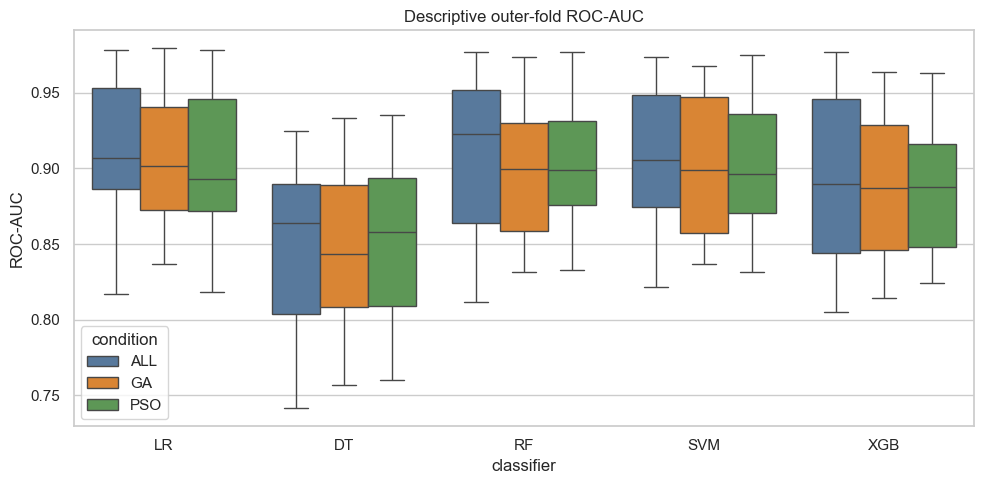

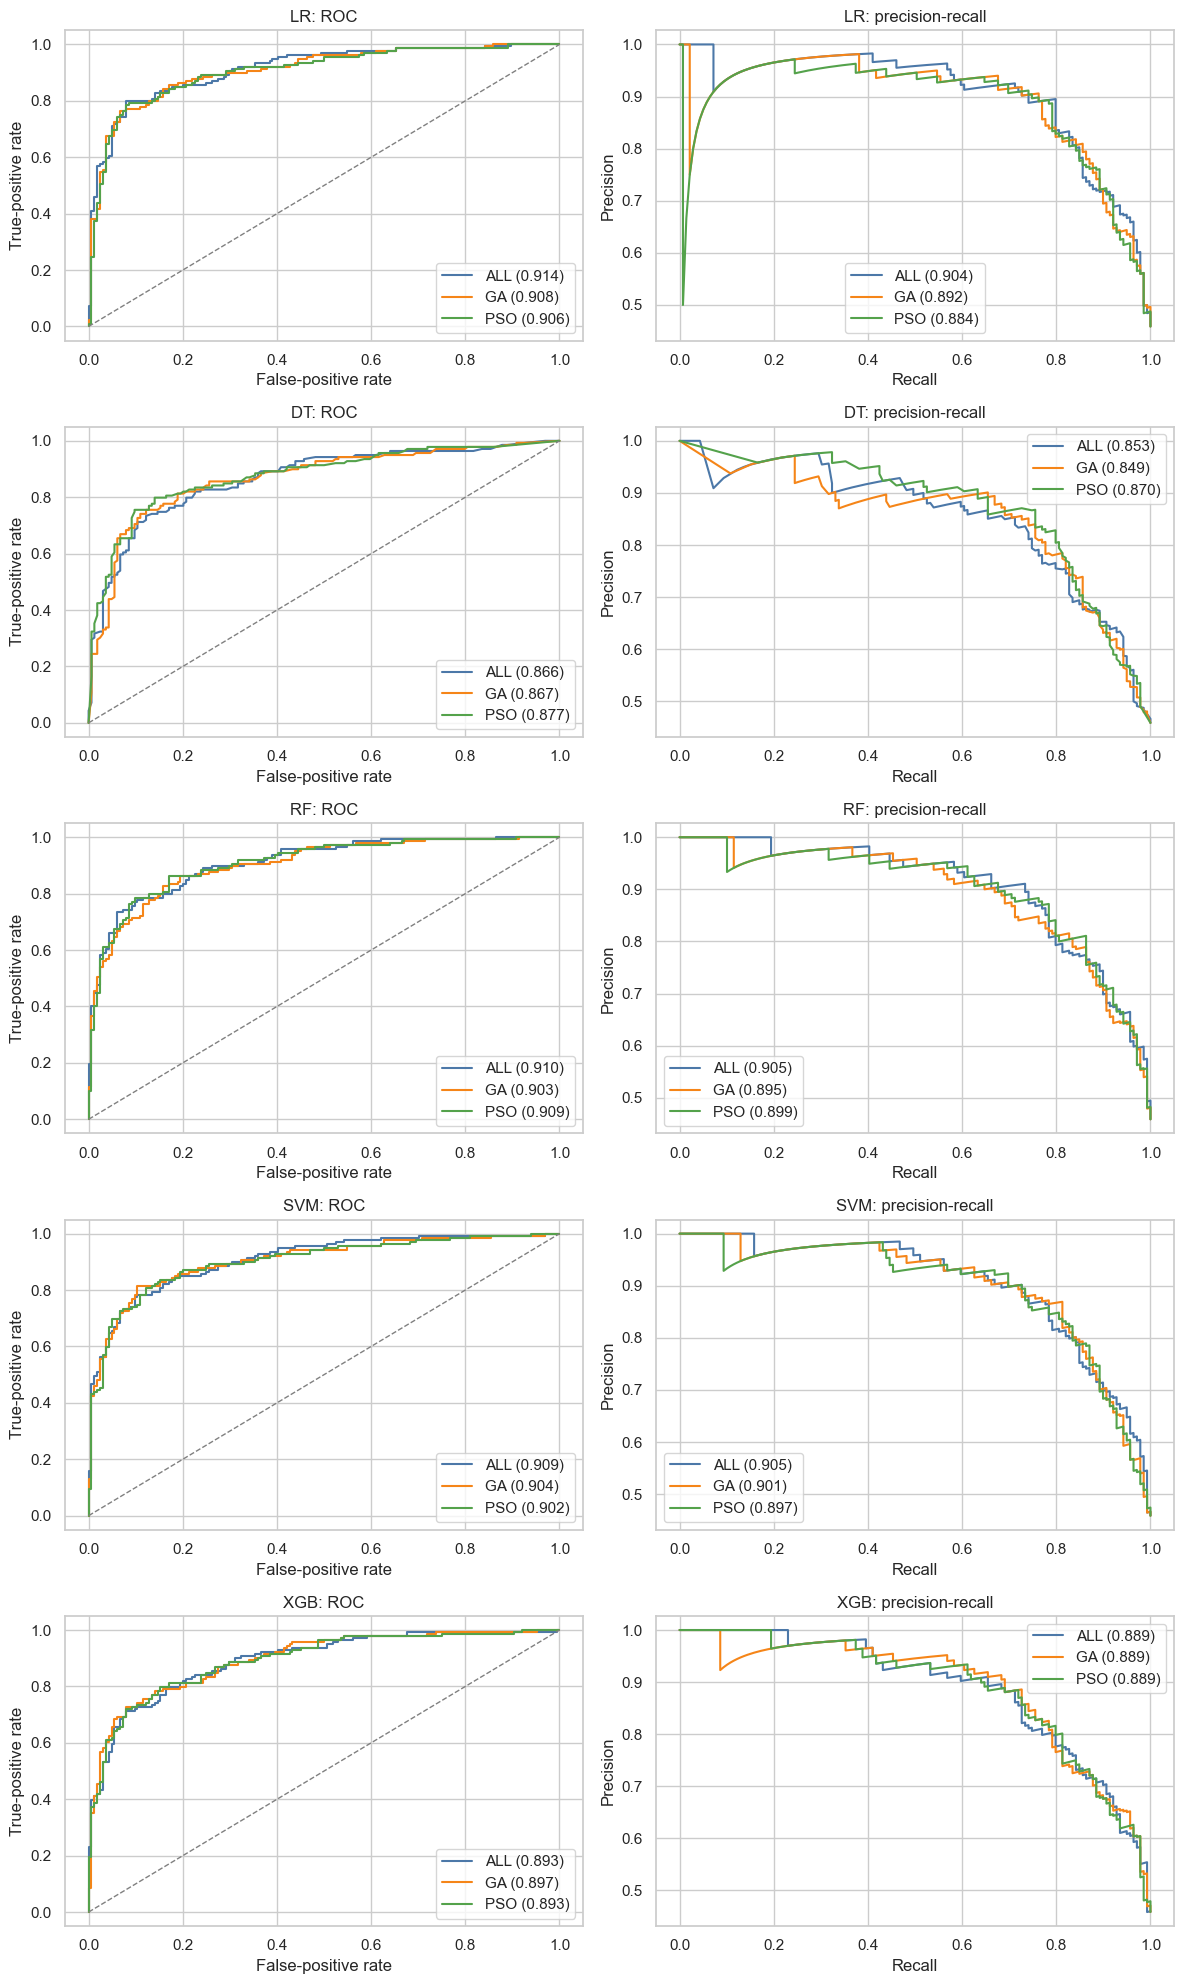

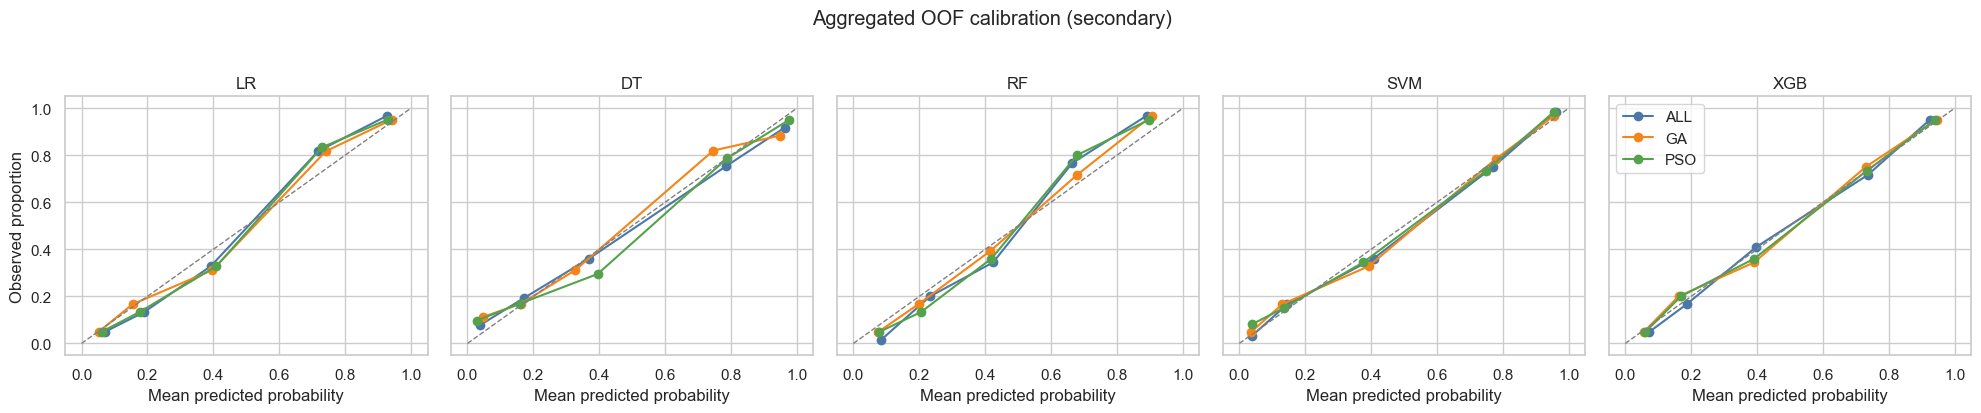

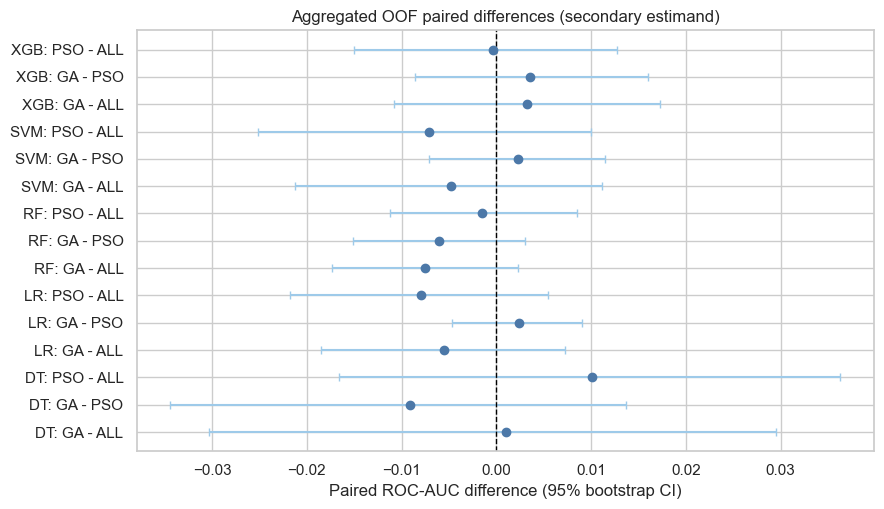

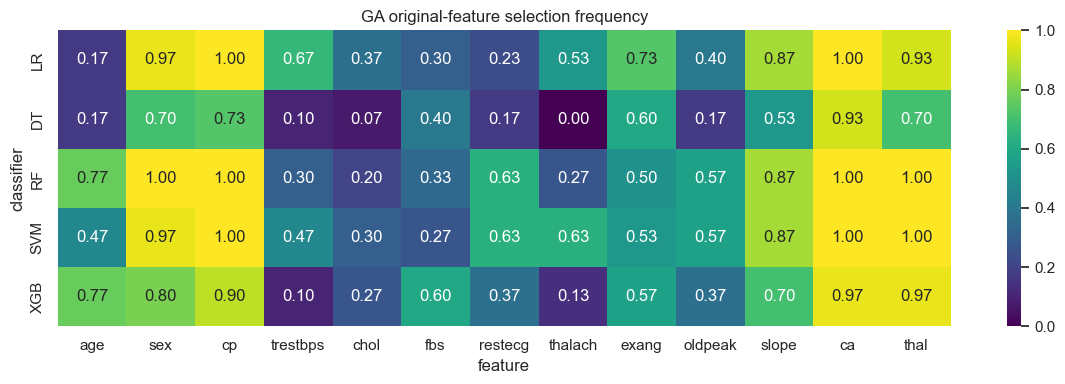

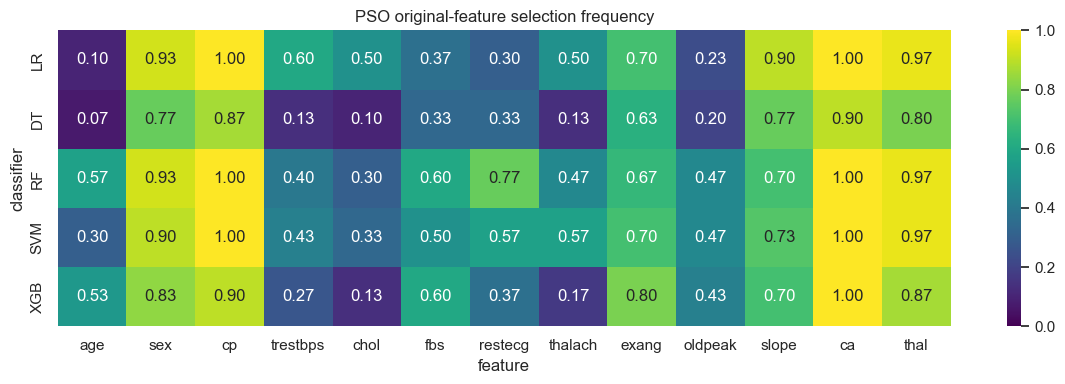

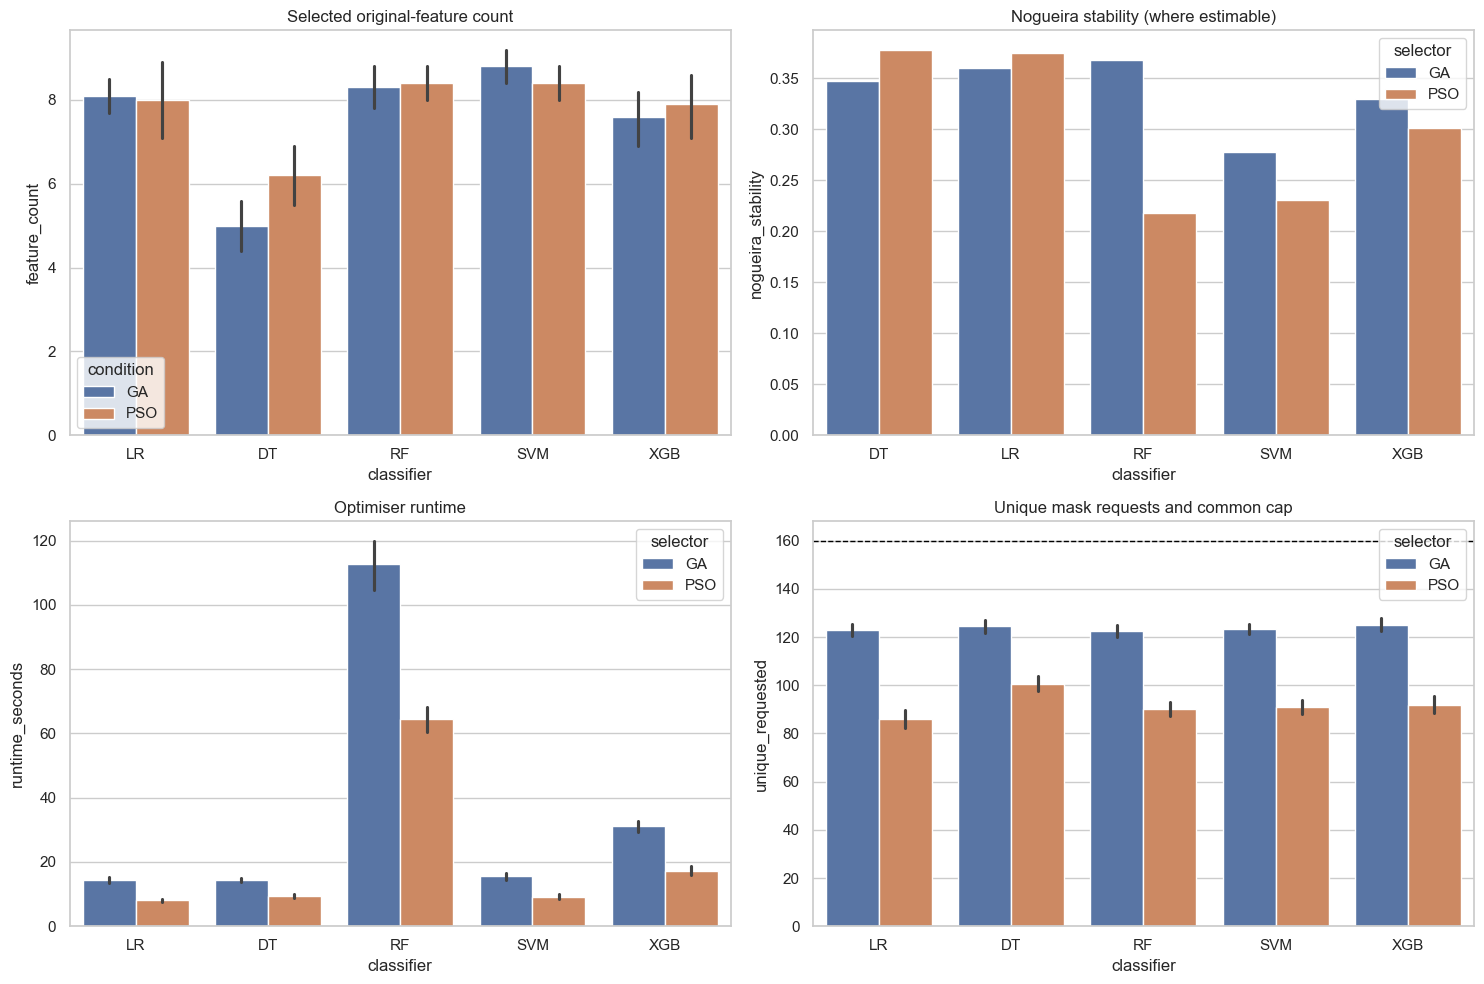

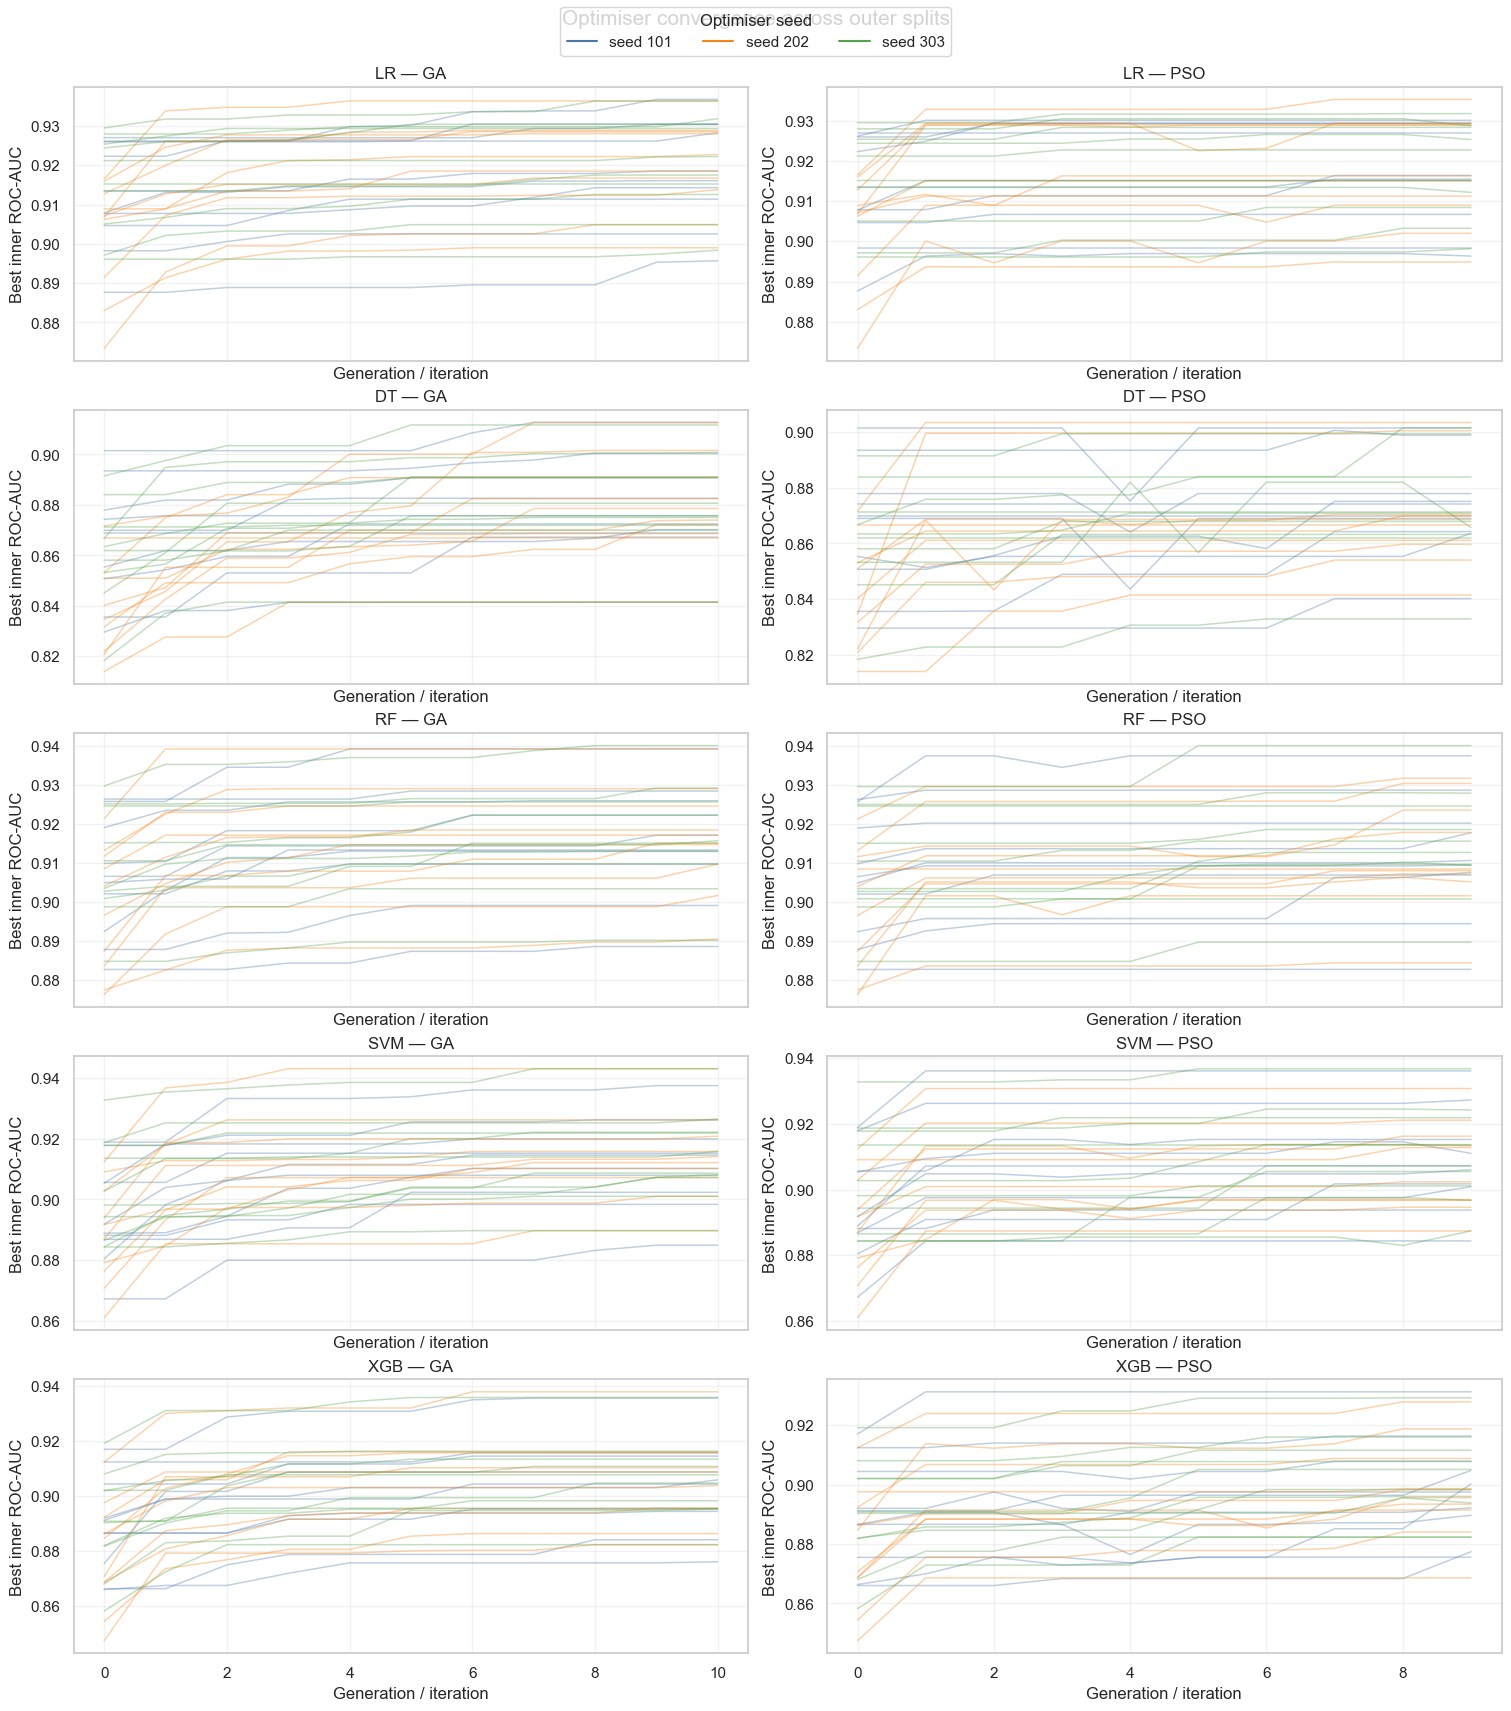

In [24]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_43", outer_split="", classifier="", selector="", seed="", condition="")
    condition_palette = {"ALL": "#4C78A8", "GA": "#F58518", "PSO": "#54A24B"}

    # Fold-level ROC-AUC distribution (descriptive)
    plt.figure(figsize=(10, 5))
    sns.boxplot(
        data=fold_metrics, x="classifier", y="roc_auc", hue="condition",
        hue_order=CONDITIONS, palette=condition_palette,
    )
    plt.title("Descriptive outer-fold ROC-AUC")
    plt.ylabel("ROC-AUC")
    with capture_warnings("21", "figure layout", "presentation"):
        plt.tight_layout()
    plt.savefig(FIGURE_DIR / "02_fold_roc_auc_distribution.png", dpi=300, bbox_inches="tight")
    plt.show()

    # Aggregated ROC and PR curves
    fig, axes = plt.subplots(len(CLASSIFIERS), 2, figsize=(12, 4 * len(CLASSIFIERS)))
    for row, classifier in enumerate(CLASSIFIERS):
        for condition in CONDITIONS:
            group = aggregated_predictions.query(
                "classifier == @classifier and condition == @condition"
            )
            if group.empty or group["y_true"].nunique() < 2:
                continue
            fpr, tpr, _ = roc_curve(group["y_true"], group["probability"])
            precision, recall, _ = precision_recall_curve(group["y_true"], group["probability"])
            auc = roc_auc_score(group["y_true"], group["probability"])
            ap = average_precision_score(group["y_true"], group["probability"])
            axes[row, 0].plot(fpr, tpr, label=f"{condition} ({auc:.3f})", color=condition_palette[condition])
            axes[row, 1].plot(recall, precision, label=f"{condition} ({ap:.3f})", color=condition_palette[condition])
        axes[row, 0].plot([0, 1], [0, 1], "--", color="grey", linewidth=1)
        axes[row, 0].set(title=f"{classifier}: ROC", xlabel="False-positive rate", ylabel="True-positive rate")
        axes[row, 1].set(title=f"{classifier}: precision-recall", xlabel="Recall", ylabel="Precision")
        axes[row, 0].legend()
        axes[row, 1].legend()
    with capture_warnings("21", "figure layout", "presentation"):
        fig.tight_layout()
    fig.savefig(FIGURE_DIR / "03_aggregated_roc_pr_curves.png", dpi=300, bbox_inches="tight")
    plt.show()

    # Calibration curves
    fig, axes = plt.subplots(1, len(CLASSIFIERS), figsize=(20, 4), sharex=True, sharey=True)
    for axis, classifier in zip(axes, CLASSIFIERS):
        for condition in CONDITIONS:
            group = aggregated_predictions.query(
                "classifier == @classifier and condition == @condition"
            )
            if group.empty:
                continue
            observed, predicted = calibration_curve(
                group["y_true"], group["probability"], n_bins=5, strategy="quantile",
            )
            axis.plot(predicted, observed, marker="o", label=condition, color=condition_palette[condition])
        axis.plot([0, 1], [0, 1], "--", color="grey", linewidth=1)
        axis.set(title=classifier, xlabel="Mean predicted probability")
    axes[0].set_ylabel("Observed proportion")
    axes[-1].legend()
    fig.suptitle("Aggregated OOF calibration (secondary)", y=1.03)
    with capture_warnings("21", "figure layout", "presentation"):
        fig.tight_layout()
    fig.savefig(FIGURE_DIR / "04_calibration_curves.png", dpi=300, bbox_inches="tight")
    plt.show()

    # Paired ROC-AUC differences
    forest = paired_roc.copy().sort_values(["classifier", "comparison"])
    forest["label"] = forest["classifier"] + ": " + forest["comparison"]
    y_positions = np.arange(len(forest))
    plt.figure(figsize=(9, max(5, 0.35 * len(forest))))
    plt.errorbar(
        forest["observed_difference"], y_positions,
        xerr=[forest["observed_difference"] - forest["ci_2_5"], forest["ci_97_5"] - forest["observed_difference"]],
        fmt="o", color="#4C78A8", ecolor="#9ECAE9", capsize=3,
    )
    plt.axvline(0, color="black", linestyle="--", linewidth=1)
    plt.yticks(y_positions, forest["label"])
    plt.xlabel("Paired ROC-AUC difference (95% bootstrap CI)")
    plt.title("Aggregated OOF paired differences (secondary estimand)")
    with capture_warnings("21", "figure layout", "presentation"):
        plt.tight_layout()
    plt.savefig(FIGURE_DIR / "05_paired_roc_auc_forest.png", dpi=300, bbox_inches="tight")
    plt.show()

    # Feature selection heatmaps
    for selector in SELECTORS:
        heat = feature_frequency.query("selector == @selector").pivot(
            index="classifier", columns="feature", values="selection_frequency"
        ).reindex(index=CLASSIFIERS, columns=FEATURES)
        plt.figure(figsize=(12, 4))
        sns.heatmap(heat, vmin=0, vmax=1, cmap="viridis", annot=True, fmt=".2f")
        plt.title(f"{selector} original-feature selection frequency")
        with capture_warnings("21", "figure layout", "presentation"):
            plt.tight_layout()
        plt.savefig(FIGURE_DIR / f"06_{selector.lower()}_selection_frequency.png", dpi=300, bbox_inches="tight")
        plt.show()

    # Parsimony, stability and efficiency
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    sns.barplot(data=selected_masks.query("condition != 'ALL'"), x="classifier", y="feature_count", hue="condition", ax=axes[0, 0])
    axes[0, 0].set_title("Selected original-feature count")
    sns.barplot(data=stability_summary, x="classifier", y="nogueira_stability", hue="selector", ax=axes[0, 1])
    axes[0, 1].set_title("Nogueira stability (where estimable)")
    sns.barplot(data=efficiency_table, x="classifier", y="runtime_seconds", hue="selector", ax=axes[1, 0])
    axes[1, 0].set_title("Optimiser runtime")
    sns.barplot(data=efficiency_table, x="classifier", y="unique_requested", hue="selector", ax=axes[1, 1])
    axes[1, 1].axhline(CONFIG.fitness_eval_budget, color="black", linestyle="--", linewidth=1)
    axes[1, 1].set_title("Unique mask requests and common cap")
    with capture_warnings("21", "figure layout", "presentation"):
        fig.tight_layout()
    fig.savefig(FIGURE_DIR / "07_parsimony_stability_runtime.png", dpi=300, bbox_inches="tight")
    plt.show()

    # Convergence histories: line colour identifies seed; alpha separates outer splits.
    seed_colours = {101: "#4C78A8", 202: "#F58518", 303: "#54A24B"}
    fig, axes = plt.subplots(
        len(CLASSIFIERS), 2, figsize=(15, 17), sharex="col",
        constrained_layout=True, squeeze=False,
    )
    for row, classifier in enumerate(CLASSIFIERS):
        for col, selector in enumerate(SELECTORS):
            axis = axes[row, col]
            group = optimiser_runs_df.query(
                "classifier == @classifier and selector == @selector"
            ).sort_values(["seed", "outer_split"])
            for _, run in group.iterrows():
                seed = int(run["seed"])
                label = f"seed {seed}" if int(run["outer_split"]) == group["outer_split"].min() else None
                axis.plot(
                    run["convergence"], color=seed_colours[seed], alpha=0.35,
                    linewidth=1.1, label=label,
                )
            axis.set_title(f"{classifier} — {selector}")
            axis.set_xlabel("Generation / iteration")
            axis.set_ylabel("Best inner ROC-AUC")
            axis.grid(alpha=0.25)

    handles = [plt.Line2D([0], [0], color=seed_colours[seed], label=f"seed {seed}") for seed in CONFIG.optimiser_seeds]
    fig.legend(handles=handles, loc="outside upper center", ncol=len(handles), title="Optimiser seed")
    fig.suptitle("Optimiser convergence across outer splits", fontsize=15)
    convergence_path = FIGURE_DIR / "08_optimiser_convergence.png"
    with capture_warnings("21", "Figure 08 save/layout", "presentation"):
        fig.savefig(convergence_path, dpi=300, bbox_inches="tight")
    plt.show()
    assert convergence_path.exists() and convergence_path.stat().st_size > 0

except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


## 22. Interpretation-support summary

This summary places aggregated-prediction performance differences and conditional
intervals alongside feature counts, stability and computational measures.

It supports comparison across several dimensions without automatically selecting
a preferred method. It does not replace the separate paired-fold summaries,
test the hypotheses or demonstrate clinical usefulness.

In [25]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_45", outer_split="", classifier="", selector="", seed="", condition="")
    roc_wide = paired_roc.pivot(
        index="classifier", columns="comparison",
        values=["observed_difference", "ci_2_5", "ci_97_5"],
    )
    roc_wide.columns = [f"aggregated_oof_roc_auc_{stat}_{comparison.replace(' ', '_')}" for stat, comparison in roc_wide.columns]
    roc_wide = roc_wide.reset_index()

    selector_summary = (
        selected_masks.query("condition != 'ALL'")
        .groupby(["classifier", "condition"], as_index=False)["feature_count"].mean()
        .rename(columns={"condition": "selector", "feature_count": "mean_feature_count"})
        .merge(stability_summary, on=["classifier", "selector"], how="left")
        .merge(
            efficiency_table.groupby(["classifier", "selector"], as_index=False)
            .agg(mean_runtime_seconds=("runtime_seconds", "mean"), mean_unique_requests=("unique_requested", "mean")),
            on=["classifier", "selector"], how="left",
        )
    )
    selector_wide = selector_summary.pivot_table(
        index="classifier", columns="selector",
        values=[
            "mean_feature_count", "nogueira_stability", "jaccard_mean",
            "mean_runtime_seconds", "mean_unique_requests",
        ],
        aggfunc="first",
    )
    selector_wide.columns = [f"{measure}_{selector}" for measure, selector in selector_wide.columns]
    selector_wide = selector_wide.reset_index()
    interpretation_support = roc_wide.merge(selector_wide, on="classifier", how="left")
    interpretation_support["roc_auc_estimand"] = "aggregated OOF; not the fold-mean hypothesis estimand"
    interpretation_support.to_csv(TABLE_DIR / "interpretation_support_summary.csv", index=False)
    display(interpretation_support)
except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


,classifier,aggregated_oof_roc_auc_observed_difference_GA_-_ALL,aggregated_oof_roc_auc_observed_difference_GA_-_PSO,aggregated_oof_roc_auc_observed_difference_PSO_-_ALL,aggregated_oof_roc_auc_ci_2_5_GA_-_ALL,aggregated_oof_roc_auc_ci_2_5_GA_-_PSO,aggregated_oof_roc_auc_ci_2_5_PSO_-_ALL,aggregated_oof_roc_auc_ci_97_5_GA_-_ALL,aggregated_oof_roc_auc_ci_97_5_GA_-_PSO,aggregated_oof_roc_auc_ci_97_5_PSO_-_ALL,jaccard_mean_GA,jaccard_mean_PSO,mean_feature_count_GA,mean_feature_count_PSO,mean_runtime_seconds_GA,mean_runtime_seconds_PSO,mean_unique_requests_GA,mean_unique_requests_PSO,nogueira_stability_GA,nogueira_stability_PSO,roc_auc_estimand
0,DT,0.000987,-0.009059,0.010046,-0.030312,-0.034417,-0.016560,0.029481,0.013648,0.036304,0.456598,0.520275,5.0,6.2,14.461108,9.504211,124.500000,100.633333,0.347691,0.378227,aggregated OOF; not the fold-mean hypothesis e...
1,LR,-0.005483,0.002413,-0.007896,-0.018513,-0.004694,-0.021758,0.007239,0.009082,0.005486,0.624144,0.626089,8.1,8.0,14.465843,8.103960,123.066667,86.066667,0.360615,0.374665,aggregated OOF; not the fold-mean hypothesis e...
2,RF,-0.007545,-0.006010,-0.001535,-0.017375,-0.015091,-0.011231,0.002282,0.003072,0.008510,0.645204,0.607337,8.3,8.4,112.646390,64.563711,122.600000,90.100000,0.367957,0.218478,aggregated OOF; not the fold-mean hypothesis e...
3,SVM,-0.004738,0.002325,-0.007063,-0.021278,-0.007107,-0.025136,0.011143,0.011495,0.009960,0.623197,0.586269,8.8,8.4,15.631022,9.173162,123.433333,90.833333,0.277438,0.230726,aggregated OOF; not the fold-mean hypothesis e...
4,XGB,0.003202,0.003597,-0.000395,-0.010752,-0.008601,-0.015004,0.017241,0.016012,0.012766,0.568415,0.559334,7.6,7.9,31.124848,17.157624,125.033333,92.000000,0.330212,0.301663,aggregated OOF; not the fold-mean hypothesis e...


## 23. Integrity assertions and method-to-code audit

The integrity table checks recorded dimensions, keys, masks, probabilities,
comparison alignment and run-mode requirements. Some rows perform explicit
data checks; others document intended fitting boundaries.

The method-to-code table identifies relevant functions and their specified
training inputs. Its independent_review=False values describe the original
record and remain unchanged.

In [26]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_47", outer_split="", classifier="", selector="", seed="", condition="")
    def run_integrity_checks() -> pd.DataFrame:
        """Return recorded workflow assertions; this is not an independent code audit."""
        checks = []
        def add(name, passed, critical=True, note=""):
            checks.append({"check": name, "status": "PASS" if bool(passed) else "FAIL", "critical": critical, "note": note})

        add("Fold contrast rows", len(paired_fold_differences) == len(CLASSIFIERS) * 3 * (1 if CONFIG.fast_mode else 10))
        add("Approved hypothesis contrasts", fold_hypothesis_summary["hypothesis_role"].eq("approved contrast").sum() == 10)
        add("Separate estimand alignment rows", len(estimand_alignment) == 15)
        add("No bootstrap intervals assigned to fold-mean summaries", not any("ci_" in c for c in fold_hypothesis_summary.columns))
        add("Exactly five classifiers", set(predictions["classifier"]) == set(CLASSIFIERS))
        add("Exactly three conditions", set(predictions["condition"]) == set(CONDITIONS))
        expected_splits = 1 if CONFIG.fast_mode else 10
        add("Expected outer splits completed", predictions["outer_split"].nunique() == expected_splits)
        test_hash_counts = fold_metrics.groupby(["outer_split", "classifier"])["test_hash"].nunique()
        add("Matched outer-test indices", test_hash_counts.eq(1).all())
        add("No duplicate prediction keys", not predictions.duplicated(["row_id", "outer_split", "classifier", "condition"]).any())
        add("All masks have 13 original-feature bits", optimiser_runs_df["mask"].apply(len).eq(13).all())
        add("Every retained optimiser mask is non-empty", optimiser_runs_df["feature_count"].gt(0).all())
        add("GA/PSO respect common unique-request cap", optimiser_runs_df["unique_requested"].le(CONFIG.fitness_eval_budget).all(), note="The cap does not equalise attempted calls or model fits")
        add("Finite probabilities", np.isfinite(predictions["probability"]).all())
        add("Probabilities in [0, 1]", predictions["probability"].between(0, 1).all())
        add("Aggregated prediction keys unique", not aggregated_predictions.duplicated(["row_id", "classifier", "condition"]).any())
        expected_prediction_count = 1 if CONFIG.fast_mode else CONFIG.outer_repeats
        add(
            "Each aggregate uses the mode-specific prediction count",
            (not aggregated_predictions.empty
             and "prediction_count" in aggregated_predictions.columns
             and aggregated_predictions["prediction_count"].eq(expected_prediction_count).all()),
            note=f"Expected {expected_prediction_count} prediction(s) per observation-condition; "
                 + ("one outer split in smoke mode; not final evidence" if CONFIG.fast_mode
                    else "complete repeated outer validation"),
        )
        add("Paired comparison rows aligned", not paired_bootstrap.empty)
        add("Classifier-specific selector recorded", optimiser_runs_df.groupby(["classifier", "selector"]).size().gt(0).all())
        add("Selection and tuning restricted by function interfaces", True, note="Recorded design assertion using frozen inner indices; no independent code audit")
        add("SVM calibration restricted by fitting function", True, note="Recorded outer-training hash; no independent code audit")
        add("Cache context excludes optimiser seed", len(sample_cache_key) == 6 and 101 not in sample_cache_key)
        add("FAST output not labelled final", (CONFIG.fast_mode and RUN_NAME.startswith("fast_v3_mon_")) or ((not CONFIG.fast_mode) and RUN_NAME.startswith("final_v3_mon_")))
        add("Final execution mode", True, critical=False, note="FAST smoke test; final-only counts not applicable" if CONFIG.fast_mode else "fast_mode=false and final execution explicitly authorised")

        if not CONFIG.fast_mode:
            expected = {
                "Analytical observations": len(X) == 303,
                "Fold metric rows": len(fold_metrics) == 150,
                "Raw prediction rows": len(predictions) == 9090,
                "Aggregated prediction rows": len(aggregated_predictions) == 4545,
                "Optimiser runs": len(optimiser_runs_df) == 300,
                "Selected mask rows": len(selected_masks) == 150,
                "Tuning rows": len(tuning_results) == 150,
                "Paired bootstrap rows": len(paired_bootstrap) == 60,
                "Stability rows": len(stability_summary) == 10,
                "Thirty retained runs per stability row": stability_summary["retained_runs"].eq(30).all(),
                "All bootstrap rows have 2000 valid replicates": paired_bootstrap["valid_replicates"].eq(2000).all(),
                "No skipped bootstrap replicates": paired_bootstrap["skipped_replicates"].eq(0).all(),
            }
            for name, passed in expected.items():
                add(name, passed, critical=True)
        return pd.DataFrame(checks)


    method_to_code_audit = pd.DataFrame([
        {"method": "Fold-local preprocessing", "function_or_stage": "build_pipeline/evaluate_mask/tune_and_evaluate", "fitting_data": "inner training or complete outer training", "independent_review": False},
        {"method": "Classifier-specific feature selection", "function_or_stage": "run_ga/run_binary_pso", "fitting_data": "outer training with frozen inner folds", "independent_review": False},
        {"method": "Condition-specific tuning", "function_or_stage": "GridSearchCV in tune_and_evaluate", "fitting_data": "outer training with frozen inner folds", "independent_review": False},
        {"method": "SVM sigmoid calibration", "function_or_stage": "CalibratedClassifierCV in tune_and_evaluate", "fitting_data": "outer training only", "independent_review": False},
    ])
    method_to_code_audit.to_csv(OUTPUT_DIR / "method_to_code_audit.csv", index=False)

    integrity_audit = run_integrity_checks()
    integrity_audit.to_csv(OUTPUT_DIR / "integrity_audit.csv", index=False)
    display(integrity_audit, method_to_code_audit)
    critical_failures = integrity_audit.query("critical and status == 'FAIL'")
    if not critical_failures.empty:
        raise RuntimeError("Critical integrity checks failed; final export is blocked.")

except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


,check,status,critical,note
0,Fold contrast rows,PASS,True,
1,Approved hypothesis contrasts,PASS,True,
2,Separate estimand alignment rows,PASS,True,
3,No bootstrap intervals assigned to fold-mean s...,PASS,True,
4,Exactly five classifiers,PASS,True,
5,Exactly three conditions,PASS,True,
6,Expected outer splits completed,PASS,True,
7,Matched outer-test indices,PASS,True,
8,No duplicate prediction keys,PASS,True,
9,All masks have 13 original-feature bits,PASS,True,


,method,function_or_stage,fitting_data,independent_review
0,Fold-local preprocessing,build_pipeline/evaluate_mask/tune_and_evaluate,inner training or complete outer training,False
1,Classifier-specific feature selection,run_ga/run_binary_pso,outer training with frozen inner folds,False
2,Condition-specific tuning,GridSearchCV in tune_and_evaluate,outer training with frozen inner folds,False
3,SVM sigmoid calibration,CalibratedClassifierCV in tune_and_evaluate,outer training only,False


## 24. Warnings, exports and manifest

The workflow saves captured warnings and fitness-error records after figure
generation. These records have defined capture limits and should not be read
as a complete account of every possible warning.

Monitoring is stopped and flushed before manifest generation. The manifest
records file identities and canonical/alias relationships for files present
when it was created. It does not automatically cover later notebook exports,
supplementary files or documentation changes.

A detached checksum verifies the saved manifest without a self-referential
checksum claim. Matching hashes support file identity, not analytical correctness.


In [27]:
try:
    if MONITOR is not None:
        MONITOR.set_context(stage="notebook_cell_49", outer_split="", classifier="", selector="", seed="", condition="")
    for _, row in stability_summary.query("nogueira_status != 'estimated'").iterrows():
        CAPTURED_WARNINGS.append({
            "timestamp_utc": datetime.now(timezone.utc).isoformat(),
            "category": "UndefinedStatistic",
            "message": f"{row['classifier']} {row['selector']} Nogueira stability: {row['nogueira_status']}",
            "section": "18", "operation": "stability", "severity": "analytical",
            "disposition": "retained as undefined with reason",
        })
    for _, row in aggregated_metrics.query("calibration_status != 'estimated'").iterrows():
        CAPTURED_WARNINGS.append({
            "timestamp_utc": datetime.now(timezone.utc).isoformat(),
            "category": "UndefinedStatistic",
            "message": f"{row['classifier']} {row['condition']} calibration: {row['calibration_status']}",
            "section": "17", "operation": "calibration", "severity": "analytical",
            "disposition": "retained as undefined with reason",
        })
    if CONFIG.fast_mode:
        CAPTURED_WARNINGS.append({
            "timestamp_utc": datetime.now(timezone.utc).isoformat(),
            "category": "RunModeNotice", "message": "FAST-mode outputs are smoke-test diagnostics, not final results.",
            "section": "24", "operation": "export", "severity": "presentation", "disposition": "recorded",
        })
    warning_payload = {
        "warnings": CAPTURED_WARNINGS,
        "warning_count": len(CAPTURED_WARNINGS),
        "fitness_error_count": len(FITNESS_ERRORS),
        "reconciled_after_figures": True,
    }
    save_json(warning_payload, OUTPUT_DIR / "warning_error_log.json")

    # Stop and flush BOTH logs before any manifest hash is taken.
    MONITOR.stop("completed")
    manifest_path = OUTPUT_DIR / "run_manifest.json"
    detached_path = OUTPUT_DIR / "run_manifest.sha256"
    for stale in [manifest_path, detached_path]:
        if stale.exists():
            stale.unlink()

    manifest_files = [artifact_metadata(path) for path in sorted(OUTPUT_DIR.rglob("*")) if path.is_file()]
    manifest = {
        "run_name": RUN_NAME,
        "mode": "FAST smoke test" if CONFIG.fast_mode else "FINAL MONITORED WORKFLOW",
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "configuration_fingerprint": CONFIG_FINGERPRINT,
        "self_checksum_policy": "The manifest cannot contain its own stable checksum; use run_manifest.sha256.",
        "files": manifest_files,
    }
    save_json(manifest, manifest_path)
    detached_digest = sha256_file(manifest_path)
    detached_path.write_text(f"{detached_digest}  {manifest_path.name}\n", encoding="utf-8")
    assert sha256_file(manifest_path) == detached_path.read_text(encoding="utf-8").split()[0]
    for item in manifest_files:
        path = OUTPUT_DIR / item["relative_path"]
        assert path.stat().st_size == item["size_bytes"] and sha256_file(path) == item["sha256"]

    print("Completed 25 analytical sections.")
    print(f"Run mode: {manifest['mode']}")
    print(f"Output directory: {OUTPUT_DIR.resolve()}")
    print(f"Captured warnings: {len(CAPTURED_WARNINGS)}; fitness errors: {len(FITNESS_ERRORS)}")
    print("Integrity rows are workflow assertions, not an independent audit.")
    print("Generated canonical/alias artifacts:")
    for item in manifest["files"]:
        suffix = f" -> alias of {item['alias_of']}" if item.get("alias_of") else ""
        print(" -", item["relative_path"], suffix)

except BaseException:
    if MONITOR is not None and not MONITOR.stopped:
        MONITOR.stop("interrupted_or_failed")
    raise


Completed 25 analytical sections.
Run mode: FINAL MONITORED WORKFLOW
Output directory: C:\Users\kama4\Desktop\UEL_DS\Dissertation\workflow_outputs\final_v3_mon_c2c87bcc95ecdf7f
Captured warnings: 0; fitness errors: 0
Integrity rows are workflow assertions, not an independent audit.
Generated canonical/alias artifacts:
 - aggregated_oof_predictions.csv 
 - all_optimiser_runs.json 
 - all_outer_predictions.csv 
 - analysis_estimands.json 
 - configuration.json 
 - data_provenance.json 
 - figures\01_class_and_missingness.png 
 - figures\02_fold_roc_auc_distribution.png 
 - figures\03_aggregated_roc_pr_curves.png 
 - figures\04_calibration_curves.png 
 - figures\05_paired_roc_auc_forest.png 
 - figures\06_ga_selection_frequency.png 
 - figures\06_pso_selection_frequency.png 
 - figures\07_parsimony_stability_runtime.png 
 - figures\08_optimiser_convergence.png 
 - fitness_errors.csv 
 - fold_metrics.csv 
 - integrity_audit.csv 
 - method_to_code_audit.csv 
 - monitoring\20261021T083841Z_5

## Methodological references

- Bengio, Y. and Grandvalet, Y. (2004) ‘No unbiased estimator of the variance of k-fold cross-validation’, *Journal of Machine Learning Research*, 5, 1089–1105. https://www.jmlr.org/papers/v5/grandvalet04a.html
- Cawley, G.C. and Talbot, N.L.C. (2010) ‘On over-fitting in model selection and subsequent selection bias in performance evaluation’, *Journal of Machine Learning Research*, 11, 2079–2107. https://www.jmlr.org/papers/v11/cawley10a.html
- Chen, T. and Guestrin, C. (2016) ‘XGBoost: A scalable tree boosting system’, *Proceedings of KDD 2016*, 785–794. https://doi.org/10.1145/2939672.2939785
- Collins, G.S. et al. (2024) ‘TRIPOD+AI statement’, *BMJ*, 385, e078378. https://doi.org/10.1136/bmj-2023-078378
- Kohavi, R. and John, G.H. (1997) ‘Wrappers for feature subset selection’, *Artificial Intelligence*, 97(1–2), 273–324. https://doi.org/10.1016/S0004-3702(97)00043-X
- Moons, K.G.M. et al. (2025) ‘PROBAST+AI’, *BMJ*, 388, e082505. https://doi.org/10.1136/bmj-2024-082505
- Nogueira, S., Sechidis, K. and Brown, G. (2018) ‘On the stability of feature selection algorithms’, *Journal of Machine Learning Research*, 18(174), 1–54. https://www.jmlr.org/papers/v18/17-514.html
- Steyerberg, E.W. et al. (2010) ‘Assessing the performance of prediction models’, *Epidemiology*, 21(1), 128–138. https://doi.org/10.1097/EDE.0b013e3181c30fb2
- UCI Machine Learning Repository (1988) *Heart Disease*. https://doi.org/10.24432/C52P4X
- Van Calster, B. et al. (2019) ‘Calibration: the Achilles heel of predictive analytics’, *BMC Medicine*, 17, 230. https://doi.org/10.1186/s12916-019-1466-7
- Varma, S. and Simon, R. (2006) ‘Bias in error estimation when using cross-validation for model selection’, *BMC Bioinformatics*, 7, 91. https://doi.org/10.1186/1471-2105-7-91

## Manual cleanup after an interruption
Normally the final manifest cell already stopped and flushed monitoring. Run this cell if you stop between cells. A stopped monitor is not restarted by continuing midway: restart the kernel and run the notebook from the beginning.

In [28]:
if MONITOR is not None and not MONITOR.stopped:
    MONITOR.stop("manual_cleanup")
